
# E-commerce Sales Forecasting and Customer Churn Prediction

## 1. Project Overview

This project analyzes Brazilian e-commerce data to understand sales performance, customer behaviour, product performance, and customer retention. It also explores sales forecasting and machine learning approaches for customer churn analysis.



## 2. Business Problem

The objective of this project is to analyze e-commerce sales data and identify important business patterns.

The project focuses on:

- Understanding sales trends and revenue performance.
- Identifying top-performing product categories.
- Analyzing customer purchasing behaviour.
- Understanding customer inactivity and retention.
- Building and evaluating sales forecasting and churn prediction models.
- Providing data-driven business recommendations.



## 3. Dataset Description

This project uses the Brazilian E-Commerce Public Dataset by Olist, available on Kaggle.

**Dataset details:**
- Source: Olist Brazilian E-Commerce Dataset
- Format: CSV files
- Data includes customers, orders, products, sellers, payments, reviews, and geolocation.
- Currency: Brazilian Real (BRL).

**Main datasets used:**
- Customers
- Orders
- Order Items
- Payments
- Reviews
- Products
- Sellers
- Geolocation
- Product Category Translation

The datasets are connected using common identifiers such as `customer_id` and `order_id`.



## 4. Importing Libraries

Import the required Python libraries for data manipulation, visualization, statistical analysis, and machine learning.

Libraries used in this project include:

- Pandas and NumPy for data manipulation.
- Matplotlib and Seaborn for data visualization.
- Scikit-learn for machine learning and model evaluation.



## 5. Data Loading and Initial Exploration

Load the Olist CSV datasets using Pandas and perform an initial inspection to understand their structure.

The initial exploration includes:

- Checking dataset dimensions (rows and columns).
- Inspecting column names and data types.
- Checking missing values.
- Identifying duplicate records.
- Understanding the overall data structure.



## 6. Data Cleaning and Preparation

Clean and prepare the raw datasets to ensure data quality and consistency before performing further analysis.

The cleaning process includes:

- Handling missing values.
- Checking and removing duplicate records where appropriate.
- Converting date columns into datetime format.
- Filtering delivered orders for completed-sales analysis.
- Joining relevant datasets using common identifiers.
- Calculating product revenue and freight charges.
- Creating the cleaned delivered sales dataset.



## 7. Exploratory Data Analysis (EDA)

Perform exploratory data analysis to identify patterns, trends, and relationships within the e-commerce data.

The analysis includes:

- Monthly sales and revenue trends.
- Order distribution and sales performance.
- Customer purchasing behaviour.
- Revenue distribution.
- Identification of important business patterns.

Visualizations are used to communicate findings and support data-driven decisions.



## 8. Product and Category Performance

Analyze product and category-level sales performance to identify the major revenue-generating categories.

The analysis includes:

- Calculating revenue by product category.
- Identifying top-performing product categories.
- Comparing revenue contributions across categories.
- Understanding product performance patterns.
- Identifying categories with strong business potential.



## 9. Customer Behaviour and Retention Analysis

Analyze customer purchasing patterns to understand customer engagement and repeat-purchase behaviour.

The analysis includes:

- Identifying unique customers.
- Calculating total orders per customer.
- Identifying one-time and repeat customers.
- Analyzing customer purchasing frequency.
- Examining customer revenue contribution.
- Understanding customer retention patterns.



## 10. Sales Forecasting

Analyze historical monthly sales data and explore future sales forecasting using time-series analysis.

The analysis includes:

- Aggregating revenue by month.
- Visualizing historical sales trends.
- Preparing chronological training and testing datasets.
- Developing a forecasting model.
- Evaluating forecasting performance.
- Understanding the limitations of forecasting with a limited historical dataset.



## 11. Customer Churn Analysis

Analyze customer inactivity using historical purchasing behaviour and a defined 180-day prediction window.

The analysis includes:
- Defining feature and prediction windows.
- Creating customer-level features.
- Identifying customers with no observed purchase during the prediction window.
- Analyzing customer inactivity and class imbalance.



## 12. Feature Engineering and Dataset Preparation

Prepare customer-level features and target labels for machine learning.

The selected features include:
- Historical total orders.
- Days since last purchase.
- Historical total revenue.

The target variable represents whether a customer had no observed purchase during the 180-day prediction window.



## 13. Machine Learning Model Development

Train and compare classification models to identify customer inactivity.

Models used:
- Dummy Classifier
- Logistic Regression
- Random Forest

A stratified train-test split is used to preserve class proportions.



## 14. Model Evaluation and Comparison

Evaluate model performance using metrics suitable for an extremely imbalanced classification problem.

Evaluation includes:
- Accuracy
- Precision and Recall
- F1-score
- Confusion Matrix
- Balanced Accuracy
- Macro F1
- Average Precision
- Classification threshold analysis



## 15. Business Insights and Recommendations

Translate analytical findings into actionable business recommendations.

The recommendations cover:
- Sales performance.
- Customer retention.
- Product category performance.
- Customer purchasing behaviour.
- Customer inactivity.
- Machine learning limitations.



## 16. Final Conclusion

This project explored Brazilian e-commerce sales, product performance, customer behaviour, sales forecasting, and customer inactivity.

The analysis identified important business patterns and developed baseline machine learning models. Severe class imbalance limited the reliability of churn prediction, highlighting the need for further feature engineering and model improvement.

The project demonstrates an end-to-end data science workflow, from data exploration and preparation to machine learning evaluation and business recommendations.


In [262]:
import sys

print(sys.version)
print(sys.executable)

3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
d:\VS CODE\Python\.venv\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

print("All libraries imported successfully!")

Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1
All libraries imported successfully!


In [4]:
import pandas as pd

customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")

products = pd.read_csv("../data/raw/olist_products_dataset.csv")

sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")

geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")

category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Customers: (99441, 5)
Orders: (99441, 8)
Order Items: (112650, 7)
Payments: (103886, 5)
Reviews: (99224, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Geolocation: (1000163, 5)
Category Translation: (71, 2)


In [6]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.columns.tolist())
    print("-" * 60)



Customers
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
------------------------------------------------------------

Orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
------------------------------------------------------------

Order Items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
------------------------------------------------------------

Payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']
------------------------------------------------------------

Reviews
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']
------------------------------------------------------------

Products
[

In [5]:
import pandas as pd
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [9]:
customer_orders = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

repeat_customers = customer_orders['customer_unique_id'].value_counts()
repeat_customers = repeat_customers[repeat_customers > 1]

print(repeat_customers)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
ca77025e7201e3b30c44b472ff346268     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
                                    ..
5126071e8e67f61789f6ce9f3af56143     2
e9a6501768a8cc1125752e157da21cc1     2
6e14116d3471123fcf057c203fd7e801     2
2cf396c9e24e7627ff042cccb209b9e6     2
7a6b4947e01039432cac229435d058ee     2
Name: count, Length: 2997, dtype: int64


In [8]:
len(repeat_customers)

2997

In [10]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [11]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [12]:
print(customers.isnull().sum())
print(orders.isnull().sum())

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [13]:
print(orders['order_status'].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [14]:
print("Duplicate orders:", orders['order_id'].duplicated().sum())
print("Duplicate customers:", customers['customer_id'].duplicated().sum())

Duplicate orders: 0
Duplicate customers: 0


In [15]:
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

In [16]:
print(orders['order_purchase_timestamp'].dtype)

datetime64[us]


In [17]:
orders['year'] = orders['order_purchase_timestamp'].dt.year
orders['month'] = orders['order_purchase_timestamp'].dt.month

print(orders[['order_purchase_timestamp', 'year', 'month']].head())

  order_purchase_timestamp  year  month
0      2017-10-02 10:56:33  2017     10
1      2018-07-24 20:41:37  2018      7
2      2018-08-08 08:38:49  2018      8
3      2017-11-18 19:28:06  2017     11
4      2018-02-13 21:18:39  2018      2


In [18]:
orders['month_name'] = orders['order_purchase_timestamp'].dt.month_name()

print(orders[['year', 'month', 'month_name']].head())

   year  month month_name
0  2017     10    October
1  2018      7       July
2  2018      8     August
3  2017     11   November
4  2018      2   February


In [19]:
print("First order:", orders['order_purchase_timestamp'].min())
print("Last order:", orders['order_purchase_timestamp'].max())

First order: 2016-09-04 21:15:19
Last order: 2018-10-17 17:30:18


In [24]:
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
category_translation = pd.read_csv("../data/raw/product_category_name_translation.csv")

In [25]:
datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Payments": payments,
    "Reviews": reviews,
    "Products": products,
    "Sellers": sellers,
    "Geolocation": geolocation,
    "Category Translation": category_translation
}

In [26]:
for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    


Customers
Series([], dtype: int64)

Orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Order Items
Series([], dtype: int64)

Payments
Series([], dtype: int64)

Reviews
review_comment_title      87656
review_comment_message    58247
dtype: int64

Products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Sellers
Series([], dtype: int64)

Geolocation
Series([], dtype: int64)

Category Translation
Series([], dtype: int64)


In [27]:
for name, df in datasets.items():
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_percent = missing_percent[missing_percent > 0]

    if not missing_percent.empty:
        print(f"\n{name}")
        print(missing_percent.round(2))


Orders
order_approved_at                0.16
order_delivered_carrier_date     1.79
order_delivered_customer_date    2.98
dtype: float64

Reviews
review_comment_title      88.34
review_comment_message    58.70
dtype: float64

Products
product_category_name         1.85
product_name_lenght           1.85
product_description_lenght    1.85
product_photos_qty            1.85
product_weight_g              0.01
product_length_cm             0.01
product_height_cm             0.01
product_width_cm              0.01
dtype: float64


In [28]:
total_revenue = order_items['price'].sum()

print("Total Product Revenue:", total_revenue)

Total Product Revenue: 13591643.7


In [29]:
total_freight = order_items['freight_value'].sum()

print("Total Freight:", total_freight)

Total Freight: 2251909.54


In [ ]:
order_revenue = (
    order_items.groupby('order_id')
    .agg(
        product_revenue=('price', 'sum'),
        total_freight=('freight_value', 'sum')
    )
    .reset_index()
)

order_revenue['total_revenue'] = (
    order_revenue['product_revenue'] +
    order_revenue['total_freight']
)

print(order_revenue.head())


                           order_id  product_revenue  total_freight  \
0  00010242fe8c5a6d1ba2dd792cb16214            58.90          13.29   
1  00018f77f2f0320c557190d7a144bdd3           239.90          19.93   
2  000229ec398224ef6ca0657da4fc703e           199.00          17.87   
3  00024acbcdf0a6daa1e931b038114c75            12.99          12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9           199.90          18.14   

   total_revenue  
0          72.19  
1         259.83  
2         216.87  
3          25.78  
4         218.04  


In [32]:
order_revenue = (
    order_items.groupby('order_id')
    .agg(
        product_revenue = ('price', 'sum'),
        total_freight = ('freight_value', 'sum')
    )
    .reset_index()
)
order_revenue['total_revenue'] = (
    order_revenue['product_revenue'] +
    order_revenue['total_freight']
)

print(order_revenue.head())

                           order_id  product_revenue  total_freight  \
0  00010242fe8c5a6d1ba2dd792cb16214            58.90          13.29   
1  00018f77f2f0320c557190d7a144bdd3           239.90          19.93   
2  000229ec398224ef6ca0657da4fc703e           199.00          17.87   
3  00024acbcdf0a6daa1e931b038114c75            12.99          12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9           199.90          18.14   

   total_revenue  
0          72.19  
1         259.83  
2         216.87  
3          25.78  
4         218.04  


In [33]:
sales_data = orders [
    [
    'order_id',
    'customer_id',
    'order_status',
    'order_purchase_timestamp'
    ]
].merge(
    order_revenue,
    on='order_id',
    how='left'
)

print(sales_data.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp  product_revenue  total_freight  \
0    delivered      2017-10-02 10:56:33            29.99           8.72   
1    delivered      2018-07-24 20:41:37           118.70          22.76   
2    delivered      2018-08-08 08:38:49           159.90          19.22   
3    delivered      2017-11-18 19:28:06            45.00          27.20   
4    delivered      2018-02-13 21:18:39            19.90           8.72   

   total_revenue  
0          38.71  
1         141.46  
2         179.12  
3          72.20  
4          28.6

In [34]:
print(sales_data.shape)

print(sales_data.isnull().sum())

print(sales_data.head())

(99441, 7)
order_id                      0
customer_id                   0
order_status                  0
order_purchase_timestamp      0
product_revenue             775
total_freight               775
total_revenue               775
dtype: int64
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp  product_revenue  total_freight  \
0    delivered      2017-10-02 10:56:33            29.99           8.72   
1    delivered      2018-07-24 20:41:37           118.70          22.76   
2    delivered      2018-08-08 08:38:49           159.90          19.22   
3    delivere

In [35]:
unmatched_orders = sales_data[
    sales_data['product_revenue'].isnull()
]

print(unmatched_orders)

                               order_id                       customer_id  \
266    8e24261a7e58791d10cb1bf9da94df5c  64a254d30eed42cd0e6c36dddb88adf0   
586    c272bcd21c287498b4883c7512019702  9582c5bbecc65eb568e2c1d839b5cba1   
687    37553832a3a89c9b2db59701c357ca67  7607cd563696c27ede287e515812d528   
737    d57e15fb07fd180f06ab3926b39edcd2  470b93b3f1cde85550fc74cd3a476c78   
1130   00b1cb0320190ca0daa2c88b35206009  3532ba38a3fd242259a514ac2b6ae6b6   
...                                 ...                               ...   
99252  aaab15da689073f8f9aa978a390a69d1  df20748206e4b865b2f14a5eabbfcf34   
99283  3a3cddda5a7c27851bd96c3313412840  0b0d6095c5555fe083844281f6b093bb   
99347  a89abace0dcc01eeb267a9660b5ac126  2f0524a7b1b3845a1a57fcf3910c4333   
99348  a69ba794cc7deb415c3e15a0a3877e69  726f0894b5becdf952ea537d5266e543   
99415  5fabc81b6322c8443648e1b21a6fef21  32c9df889d41b0ee8309a5efb6855dcb   

      order_status order_purchase_timestamp  product_revenue  total_freight

In [36]:
unmatched_orders['order_status'].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [37]:
sales_data['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [39]:
delivered_sales = sales_data[sales_data['order_status'] == 'delivered']
print(delivered_sales.shape)

total_product_revenue = delivered_sales['product_revenue'].sum()
print("Total Product Revenue:",total_product_revenue)

(96478, 7)
Total Product Revenue: 13221498.11


In [42]:
delivered_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_sales['order_purchase_timestamp']
    )

delivered_sales['year'] = delivered_sales['order_purchase_timestamp'].dt.year

delivered_sales['month'] = delivered_sales['order_purchase_timestamp'].dt.month

monthly_sales = (delivered_sales.groupby(['year', 'month'])
                 ['product_revenue'].sum()
                 .reset_index()
                 )

print(monthly_sales)

    year  month  product_revenue
0   2016      9           134.97
1   2016     10         40325.11
2   2016     12            10.90
3   2017      1        111798.36
4   2017      2        234223.40
5   2017      3        359198.85
6   2017      4        340669.68
7   2017      5        489338.25
8   2017      6        421923.37
9   2017      7        481604.52
10  2017      8        554699.70
11  2017      9        607399.67
12  2017     10        648247.65
13  2017     11        987765.37
14  2017     12        726033.19
15  2018      1        924645.00
16  2018      2        826437.13
17  2018      3        953356.25
18  2018      4        973534.09
19  2018      5        977544.69
20  2018      6        856077.86
21  2018      7        867953.46
22  2018      8        838576.64


In [43]:
highest_revenue_month = monthly_sales.loc[monthly_sales['product_revenue'].idxmax()]
print("Month with highest revenue:", highest_revenue_month)

Month with highest revenue: year                 2017.00
month                  11.00
product_revenue    987765.37
Name: 13, dtype: float64


In [44]:
monthly_sales = monthly_sales.sort_values(
    by=['year', 'month']
).reset_index(drop=True)

monthly_sales['revenue_growth_pct'] = ( 
    monthly_sales['product_revenue'].pct_change()*100
)

print(monthly_sales)

    year  month  product_revenue  revenue_growth_pct
0   2016      9           134.97                 NaN
1   2016     10         40325.11        2.977709e+04
2   2016     12            10.90       -9.997297e+01
3   2017      1        111798.36        1.025573e+06
4   2017      2        234223.40        1.095052e+02
5   2017      3        359198.85        5.335737e+01
6   2017      4        340669.68       -5.158471e+00
7   2017      5        489338.25        4.364009e+01
8   2017      6        421923.37       -1.377674e+01
9   2017      7        481604.52        1.414502e+01
10  2017      8        554699.70        1.517743e+01
11  2017      9        607399.67        9.500631e+00
12  2017     10        648247.65        6.725058e+00
13  2017     11        987765.37        5.237469e+01
14  2017     12        726033.19       -2.649740e+01
15  2018      1        924645.00        2.735575e+01
16  2018      2        826437.13       -1.062114e+01
17  2018      3        953356.25        1.5357

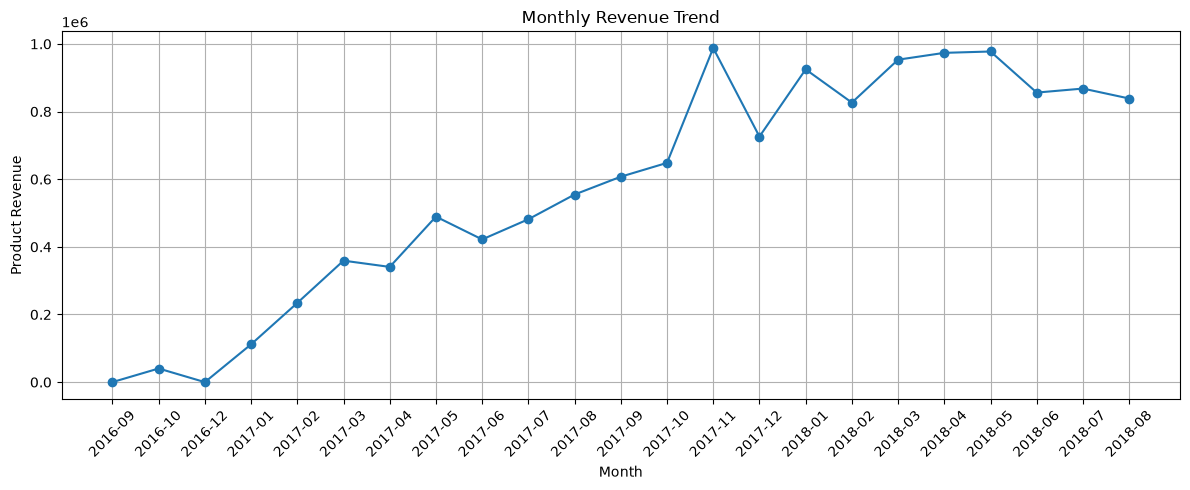

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(monthly_sales['year'].astype(str) + '-' +
         monthly_sales['month'].astype(str).str.zfill(2),
         monthly_sales['product_revenue'],
         marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Product Revenue')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [49]:
yearly_sales = (monthly_sales.groupby('year')['product_revenue'].sum().reset_index())

print(yearly_sales)

   year  product_revenue
0  2016         40470.98
1  2017       5962902.01
2  2018       7218125.12


In [52]:
yearly_sales['revenue_growth_pct'] = (
    yearly_sales['product_revenue'].pct_change()*100
)

print(yearly_sales)

   year  product_revenue  revenue_growth_pct
0  2016         40470.98                 NaN
1  2017       5962902.01        14633.772224
2  2018       7218125.12           21.050541


In [54]:
yearly_revenue = (delivered_sales.groupby('year')
                  ['product_revenue'].sum().
                  reset_index())
print(yearly_revenue)

   year  product_revenue
0  2016         40470.98
1  2017       5962902.01
2  2018       7218125.12


In [55]:
for name, df in datasets.items():
    duplicate_count = df.duplicated().sum()

    print(name, ":", duplicate_count)

Customers : 0
Orders : 0
Order Items : 0
Payments : 0
Reviews : 0
Products : 0
Sellers : 0
Geolocation : 261831
Category Translation : 0


In [57]:
missing_by_status = (
    orders.groupby('order_status')['order_delivered_customer_date']
    .apply(lambda x: x.isnull().sum())
)

print(missing_by_status)

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64


In [58]:
missing_count = products['product_category_name'].isnull().sum()

missing_percentage = (missing_count / len(products)) * 100

print("Missing Categories:", missing_count)
print("Missing Percentage:", missing_percentage, "%")

Missing Categories: 610
Missing Percentage: 1.8512336499650999 %


In [60]:
review_count = len(reviews)
missing_comments = reviews['review_comment_message'].isnull().sum()
review_with_score = reviews['review_score'].notnull().sum()

print("Total Reviews:", review_count)
print("Missing Comments:", missing_comments)
print("Reviews with Score:", review_with_score)

Total Reviews: 99224
Missing Comments: 58247
Reviews with Score: 99224


In [61]:
customer_orders_check = orders.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left',
    indicator=True
)

print(customer_orders_check['_merge'].value_counts())
print("Total rows after merge:", len(customer_orders_check))
print("Original orders:", len(orders))

_merge
both          99441
left_only         0
right_only        0
Name: count, dtype: int64
Total rows after merge: 99441
Original orders: 99441


In [62]:
delivered_customer_sales = delivered_sales.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

delivered_customer_sales = delivered_customer_sales[
    [
        'order_id',
        'customer_id',
        'customer_unique_id',
        'order_purchase_timestamp',
        'product_revenue',
        "total_freight"
    ]
]

print("Shape:", delivered_customer_sales.shape)

print("\nColumns:")
print(delivered_customer_sales.columns.tolist())

print("\nFirst five rows:")
print(delivered_customer_sales.head())

Shape: (96478, 6)

Columns:
['order_id', 'customer_id', 'customer_unique_id', 'order_purchase_timestamp', 'product_revenue', 'total_freight']

First five rows:
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

                 customer_unique_id order_purchase_timestamp  product_revenue  \
0  7c396fd4830fd04220f754e42b4e5bff      2017-10-02 10:56:33            29.99   
1  af07308b275d755c9edb36a90c618231      2018-07-24 20:41:37           118.70   
2  3a653a41f6f9fc3d2a113cf8398680e8      2018-08-08 08:38:49           159.90   
3  7c142cf63193a1473d2e66489a9ae977      2017-11-18 19:28:06            45.00

In [63]:
print("Duplicate rows:", delivered_customer_sales.duplicated().sum())

print("\nMissing values:")
print(delivered_customer_sales.isnull().sum())

print(
    "\nDuplicate order IDs:",
    delivered_customer_sales['order_id'].duplicated().sum()
)

print("\nDataset shape:", delivered_customer_sales.shape)





Duplicate rows: 0

Missing values:
order_id                    0
customer_id                 0
customer_unique_id          0
order_purchase_timestamp    0
product_revenue             0
total_freight               0
dtype: int64

Duplicate order IDs: 0

Dataset shape: (96478, 6)


In [70]:
delivered_customer_sales.to_csv(
    '../data/cleaned_delivered_sales.csv',
    index=False
)

In [67]:
import os

print(os.getcwd())

d:\VS CODE\Data_Science_Projects\Project_1_Ecommerce\notebooks


In [68]:
import os

print(os.path.exists('data/cleaned_delivered_sales.csv'))

False


In [71]:
import pandas as pd

sales =pd.read_csv("../data/cleaned_delivered_sales.csv")

In [72]:
total_product_revenue = delivered_customer_sales['product_revenue'].sum()

total_delivered_orders = delivered_customer_sales['order_id'].nunique()

aov = (total_product_revenue / total_delivered_orders)

total_unique_customers = delivered_customer_sales['customer_unique_id'].nunique()

print("Total product revenue:", total_product_revenue)
print("Total delivered orders:", total_delivered_orders)
print("Average Order Value (AOV):", aov)
print("Total unique customers:", total_unique_customers)


Total product revenue: 13221498.11
Total delivered orders: 96478
Average Order Value (AOV): 137.0415857501192
Total unique customers: 93358


In [78]:
delivered_customer_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_customer_sales['order_purchase_timestamp']
)

delivered_customer_sales['year'] = (delivered_customer_sales['order_purchase_timestamp'].dt.year)

delivered_customer_sales['month'] = (delivered_customer_sales['order_purchase_timestamp'].dt.month)

monthly_revenue = (delivered_customer_sales.groupby(['year', 'month']) ['product_revenue'].sum().reset_index())

monthly_revenue = monthly_revenue.sort_values(by=['year', 'month']).reset_index(drop=True)

print(monthly_revenue)

    year  month  product_revenue
0   2016      9           134.97
1   2016     10         40325.11
2   2016     12            10.90
3   2017      1        111798.36
4   2017      2        234223.40
5   2017      3        359198.85
6   2017      4        340669.68
7   2017      5        489338.25
8   2017      6        421923.37
9   2017      7        481604.52
10  2017      8        554699.70
11  2017      9        607399.67
12  2017     10        648247.65
13  2017     11        987765.37
14  2017     12        726033.19
15  2018      1        924645.00
16  2018      2        826437.13
17  2018      3        953356.25
18  2018      4        973534.09
19  2018      5        977544.69
20  2018      6        856077.86
21  2018      7        867953.46
22  2018      8        838576.64


In [81]:
highest_revenue_index = monthly_revenue['product_revenue'].idxmax()

highest_revenue_month = monthly_revenue.loc[highest_revenue_index]

print("Year:", highest_revenue_month['year'])
print("Month:", highest_revenue_month['month'])
print("Highest Product Revenue:", highest_revenue_month['product_revenue'])

Year: 2017.0
Month: 11.0
Highest Product Revenue: 987765.37


In [83]:
monthly_revenue['revenue_growth_pct'] = (monthly_revenue['product_revenue'].pct_change()*100)

print(monthly_revenue)

    year  month  product_revenue  revenue_growth_pct
0   2016      9           134.97                 NaN
1   2016     10         40325.11        2.977709e+04
2   2016     12            10.90       -9.997297e+01
3   2017      1        111798.36        1.025573e+06
4   2017      2        234223.40        1.095052e+02
5   2017      3        359198.85        5.335737e+01
6   2017      4        340669.68       -5.158471e+00
7   2017      5        489338.25        4.364009e+01
8   2017      6        421923.37       -1.377674e+01
9   2017      7        481604.52        1.414502e+01
10  2017      8        554699.70        1.517743e+01
11  2017      9        607399.67        9.500631e+00
12  2017     10        648247.65        6.725058e+00
13  2017     11        987765.37        5.237469e+01
14  2017     12        726033.19       -2.649740e+01
15  2018      1        924645.00        2.735575e+01
16  2018      2        826437.13       -1.062114e+01
17  2018      3        953356.25        1.5357

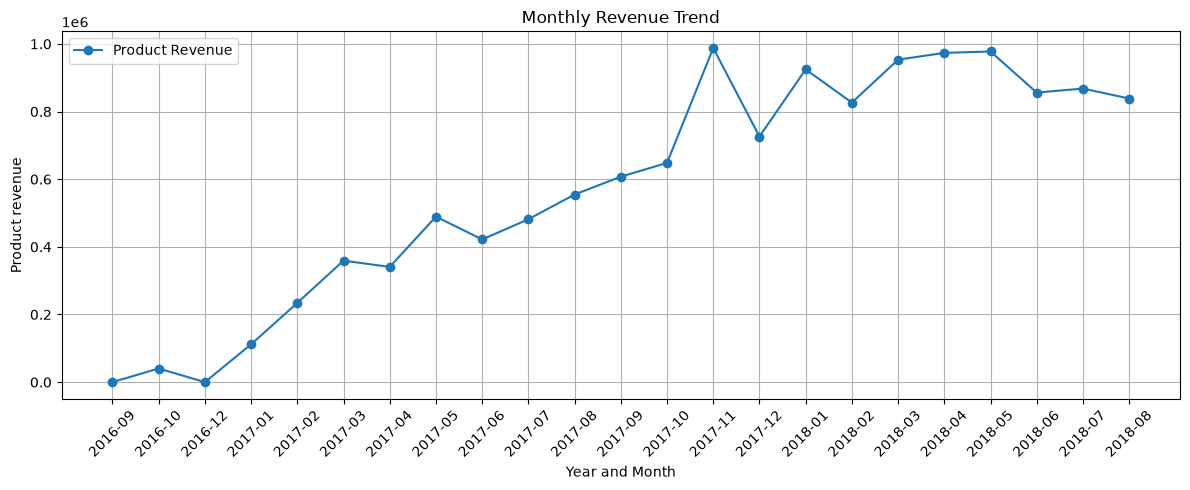

In [89]:
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 5))

plt.plot(monthly_revenue['year'].astype(str) + '-' + monthly_revenue['month'].astype(str).str.zfill(2), monthly_revenue['product_revenue'], marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Year and Month")
plt.ylabel("Product revenue")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.legend(["Product Revenue"])

plt.show()

In [90]:
total_product_revenue = monthly_revenue.groupby('year')['product_revenue'].sum().reset_index()
print(total_product_revenue)

   year  product_revenue
0  2016         40470.98
1  2017       5962902.01
2  2018       7218125.12


In [92]:
total_product_revenue['revenue_growth_pct'] = (total_product_revenue['product_revenue'].pct_change()*100)
print(total_product_revenue)

   year  product_revenue  revenue_growth_pct
0  2016         40470.98                 NaN
1  2017       5962902.01        14633.772224
2  2018       7218125.12           21.050541


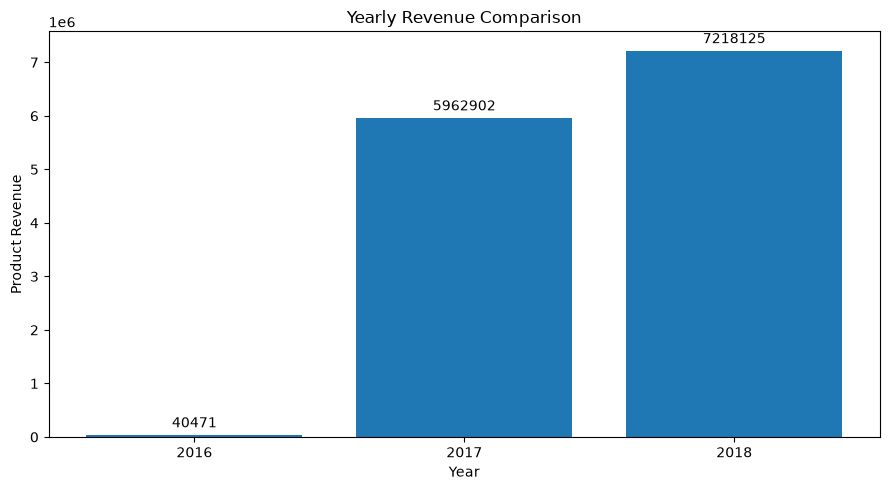

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    total_product_revenue['year'].astype(str),
    total_product_revenue['product_revenue']
)

plt.title('Yearly Revenue Comparison')
plt.xlabel('Year')
plt.ylabel('Product Revenue')

plt.bar_label(bars, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

In [98]:
customer_order_counts = delivered_customer_sales['customer_unique_id'].value_counts()

total_unique_customers = customer_order_counts.count()

repeated_customers = customer_order_counts[customer_order_counts > 1]
total_repeat_customers = len(repeated_customers)

repeat_customer_percentage = (
    total_repeat_customers / total_unique_customers
) * 100


print("Total Unique Customers:", total_unique_customers)
print("Repeat Customers:", total_repeat_customers)
print("Repeat Customer Percentage:", round(repeat_customer_percentage, 2), "%")


Total Unique Customers: 93358
Repeat Customers: 2801
Repeat Customer Percentage: 3.0 %


In [99]:
print(total_product_revenue)

   year  product_revenue  revenue_growth_pct
0  2016         40470.98                 NaN
1  2017       5962902.01        14633.772224
2  2018       7218125.12           21.050541


In [101]:
product_sales = order_items.merge(
    products,
    on='product_id',
    how='left'
)

print("Shape:", product_sales.shape)
print("/nFirst five rows:", product_sales.head())
print("\nColumn names:", product_sales.columns.tolist())

Shape: (112650, 15)
/nFirst five rows:                            order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value product_category_name  \
0  2017-09-19 09:45:35   58.90          13.29            cool_stuff   
1  2017-05-03 11:05:13  239.90          19.93          

In [102]:
product_sales = product_sales.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

print(product_sales.head())

print(product_sales.shape)


                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value product_category_name  \
0  2017-09-19 09:45:35   58.90          13.29            cool_stuff   
1  2017-05-03 11:05:13  239.90          19.93              pet_shop   
2  2018-01-18 14:48:30 

In [103]:
print("Missing Portuguese Categories:")
print(product_sales['product_category_name'].isnull().sum())

print("\nMissing English Categories:")
print(product_sales['product_category_name_english'].isnull().sum())

missing_percentage = (
    product_sales['product_category_name_english'].isnull().mean() * 100
)

print("\nMissing English Category  Percentage:", round(missing_percentage, 2), "%")

Missing Portuguese Categories:
1603

Missing English Categories:
1627

Missing English Category  Percentage: 1.44 %


In [109]:
category_revenue = (
    product_sales.groupby('product_category_name_english')['price']
    .sum()
    .reset_index()
)

category_revenue = category_revenue.sort_values(
    by='price',
    ascending=False
).reset_index(drop=True)

print(category_revenue.head(10))

  product_category_name_english       price
0                 health_beauty  1258681.34
1                 watches_gifts  1205005.68
2                bed_bath_table  1036988.68
3                sports_leisure   988048.97
4         computers_accessories   911954.32
5               furniture_decor   729762.49
6                    cool_stuff   635290.85
7                    housewares   632248.66
8                          auto   592720.11
9                  garden_tools   485256.46


In [110]:
print(category_revenue.head())

  product_category_name_english       price
0                 health_beauty  1258681.34
1                 watches_gifts  1205005.68
2                bed_bath_table  1036988.68
3                sports_leisure   988048.97
4         computers_accessories   911954.32


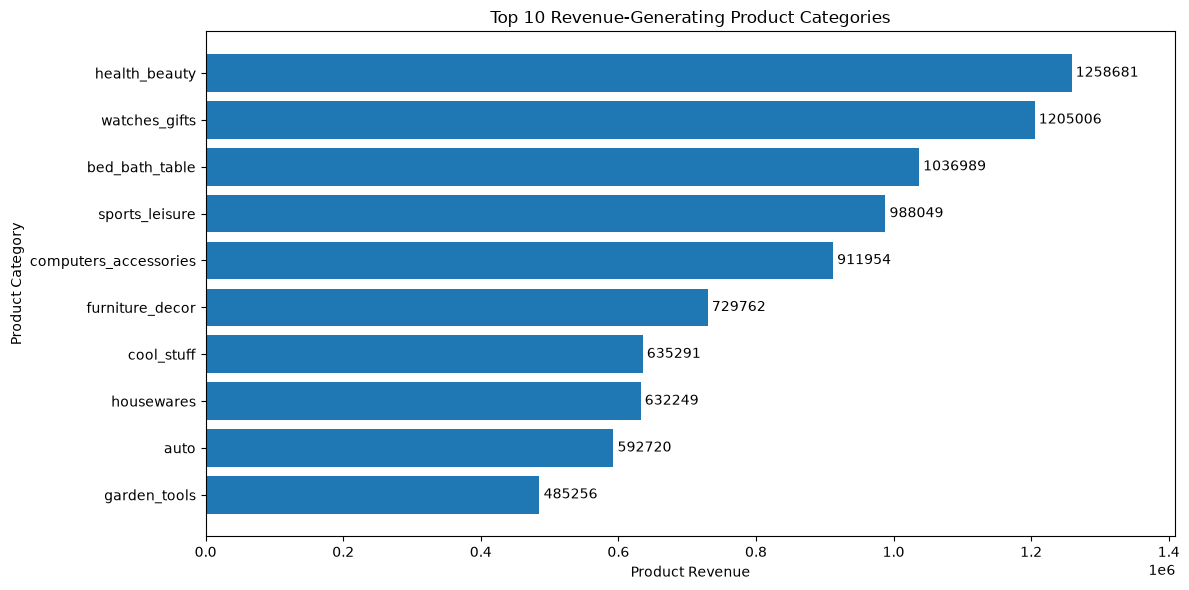

In [122]:
import matplotlib.pyplot as plt

top_10_categories = category_revenue.head(10)

plt.figure(figsize=(12, 6))

bars = plt.barh(top_10_categories['product_category_name_english'],
         top_10_categories['price'])

plt.xlim(0, top_10_categories['price'].max() * 1.12)
plt.bar_label(bars, fmt='%.0f', padding=3)
plt.title('Top 10 Revenue-Generating Product Categories')
plt.xlabel('Product Revenue')
plt.ylabel('Product Category')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [114]:
category_orders = (
    product_sales.groupby('product_category_name_english')['product_id']
    .count().reset_index()
)

category_orders = category_orders.sort_values(
    by='product_id',
    ascending=False
).reset_index(drop=True)

category_orders.head(10)

,product_category_name_english,product_id
0,bed_bath_table,11115
1,health_beauty,9670
2,sports_leisure,8641
3,furniture_decor,8334
4,computers_accessories,7827
5,housewares,6964
6,watches_gifts,5991
7,telephony,4545
8,garden_tools,4347
9,auto,4235


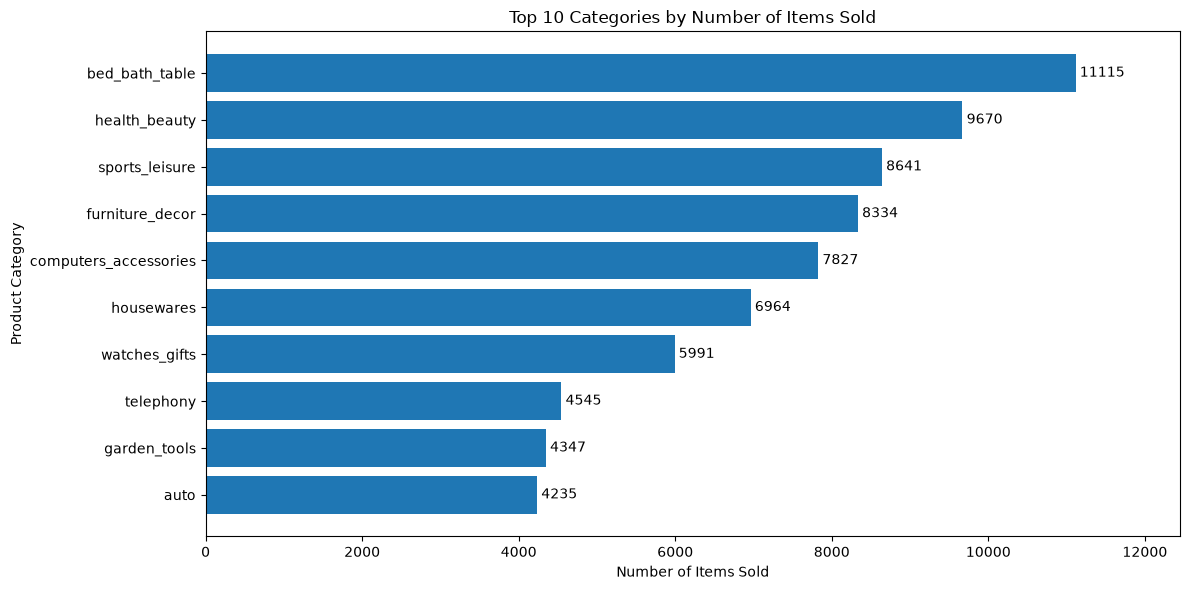

In [123]:
import matplotlib.pyplot as plt 

top_10_orders = category_orders.head(10)

plt.figure(figsize=(12, 6))

bars = plt.barh(top_10_orders['product_category_name_english'],
                top_10_orders['product_id']
                )

plt.title('Top 10 Categories by Number of Items Sold')
plt.xlabel('Number of Items Sold')
plt.ylabel('Product Category')

plt.gca().invert_yaxis()

plt.xlim(0, top_10_orders['product_id'].max() * 1.12)
plt.bar_label(bars, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

In [126]:
category_performance = category_revenue.merge(
    category_orders,
    on='product_category_name_english',
    how='inner'
)

category_performance = category_performance.rename(
    columns={
        'price': 'total_revenue',
        'product_id': 'items_sold'
    }
)

category_performance = category_performance.sort_values(
    by='total_revenue',
    ascending=False
)

category_performance.head(10)

,product_category_name_english,total_revenue,items_sold
0,health_beauty,1258681.34,9670
1,watches_gifts,1205005.68,5991
2,bed_bath_table,1036988.68,11115
3,sports_leisure,988048.97,8641
4,computers_accessories,911954.32,7827
5,furniture_decor,729762.49,8334
6,cool_stuff,635290.85,3796
7,housewares,632248.66,6964
8,auto,592720.11,4235
9,garden_tools,485256.46,4347


In [133]:
customer_frequency = (delivered_customer_sales
                      .groupby('customer_unique_id')['order_id']
                      .nunique()
                      .reset_index()
                      .rename(columns={'order_id': 'total_orders'})
)

customer_frequency.sort_values(
    by = 'total_orders',
    ascending = False
).head(20)

,customer_unique_id,total_orders
51431,8d50f5eadf50201ccdcedfb9e2ac8455,15
22779,3e43e6105506432c953e165fb2acf44c,9
36706,6469f99c1f9dfae7733b25662e7f1782,7
10060,1b6c7548a2a1f9037c1fd3ddfed95f33,7
73921,ca77025e7201e3b30c44b472ff346268,7
26257,47c1a3033b8b77b3ab6e109eb4d5fdf3,6
80538,dc813062e0fc23409cd255f7f53c7074,6
36500,63cfc61cee11cbe306bff5857d00bfe4,6
87885,f0e310a6839dce9de1638e0fe5ab282a,6
6964,12f5d6e1cbf93dafd9dcc19095df0b3d,6


In [134]:
frequency_distribution = (
    customer_frequency['total_orders']
    .value_counts()
    .sort_index()
)

print(frequency_distribution)

total_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


In [136]:
one_time_customers = len(
    customer_frequency[customer_frequency['total_orders'] == 1]
)

repeat_customers = len(
    customer_frequency[customer_frequency['total_orders'] > 1]
)

total_customers = len(customer_frequency)

one_time_percentage = (
    one_time_customers / total_customers
) * 100

repeat_percentage = (
    repeat_customers / total_customers
) * 100


print("Total one-time customers:", one_time_customers)
print("Total repeat customers:", repeat_customers)
print("Percentage of one-time customers:", round(one_time_percentage, 2), "%")
print("Percentage of repeat customers:", round(repeat_percentage, 2), "%")

Total one-time customers: 90557
Total repeat customers: 2801
Percentage of one-time customers: 97.0 %
Percentage of repeat customers: 3.0 %


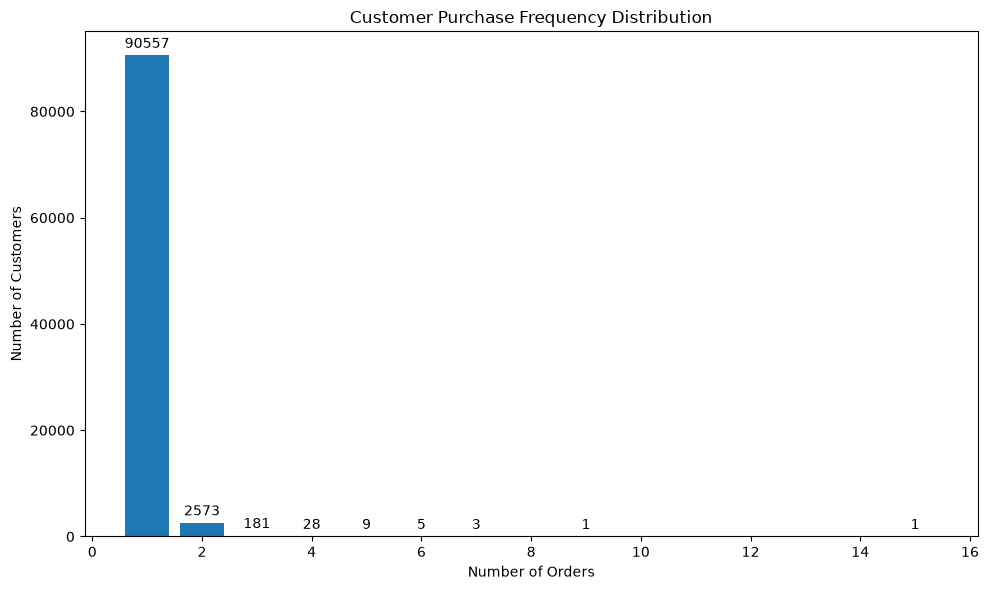

In [137]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    frequency_distribution.index,
    frequency_distribution.values
)

plt.title('Customer Purchase Frequency Distribution')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')

plt.bar_label(bars, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

In [139]:
customer_revenue = (
    delivered_customer_sales
    .groupby('customer_unique_id')['product_revenue']
    .sum()
    .reset_index()
    .rename(columns={'product_revenue': 'customer_revenue'})
    .sort_values(by='customer_revenue', ascending=False)
)

customer_revenue = customer_revenue.reset_index(drop=True)

customer_revenue.head(10)

,customer_unique_id,customer_revenue
0,0a0a92112bd4c708ca5fde585afaa872,13440.0
1,da122df9eeddfedc1dc1f5349a1a690c,7388.0
2,763c8b1c9c68a0229c42c9fc6f662b93,7160.0
3,dc4802a71eae9be1dd28f5d788ceb526,6735.0
4,459bef486812aa25204be022145caa62,6729.0
5,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0
6,4007669dec559734d6f53e029e360987,5934.6
7,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0
8,48e1ac109decbb87765a3eade6854098,4590.0
9,a229eba70ec1c2abef51f04987deb7a5,4400.0


In [140]:
# 1. Total customer revenue
total_customer_revenue = customer_revenue['customer_revenue'].sum()

# 2. Total unique customers
total_unique_customers = customer_revenue['customer_unique_id'].nunique()

# 3. Average customer revenue
average_customer_revenue = (
    total_customer_revenue / total_unique_customers
)

# Display results
print("Total Customer Revenue:", round(total_customer_revenue, 2))
print("Total Unique Customers:", total_unique_customers)
print("Average Customer Revenue:", round(average_customer_revenue, 2))

Total Customer Revenue: 13221498.11
Total Unique Customers: 93358
Average Customer Revenue: 141.62


In [141]:
# 1. Filter repeat customers
repeat_customer_data = customer_frequency[
    customer_frequency['total_orders'] > 1
]

# 2. Merge with customer revenue
repeat_customer_analysis = repeat_customer_data.merge(
    customer_revenue,
    on='customer_unique_id',
    how='inner'
)

# 3. Sort by total orders (highest to lowest)
repeat_customer_analysis = repeat_customer_analysis.sort_values(
    by='total_orders',
    ascending=False
)

# 4. Display top 10 customers
repeat_customer_analysis.head(10)

,customer_unique_id,total_orders,customer_revenue
1551,8d50f5eadf50201ccdcedfb9e2ac8455,15,714.63
670,3e43e6105506432c953e165fb2acf44c,9,1000.85
2233,ca77025e7201e3b30c44b472ff346268,7,806.61
308,1b6c7548a2a1f9037c1fd3ddfed95f33,7,809.21
1089,6469f99c1f9dfae7733b25662e7f1782,7,664.20
1078,63cfc61cee11cbe306bff5857d00bfe4,6,579.81
209,12f5d6e1cbf93dafd9dcc19095df0b3d,6,58.40
767,47c1a3033b8b77b3ab6e109eb4d5fdf3,6,836.60
2663,f0e310a6839dce9de1638e0fe5ab282a,6,438.09
2426,dc813062e0fc23409cd255f7f53c7074,6,687.76


In [142]:
# 1. Average delivered orders per unique customer
average_orders = customer_frequency['total_orders'].mean()

# 2. Maximum orders placed by a single customer
maximum_orders = customer_frequency['total_orders'].max()

# 3. Median orders per customer
median_orders = customer_frequency['total_orders'].median()

# Display results
print("Average Orders per Customer:", round(average_orders, 2))
print("Maximum Orders by a Single Customer:", maximum_orders)
print("Median Orders per Customer:", median_orders)

Average Orders per Customer: 1.03
Maximum Orders by a Single Customer: 15
Median Orders per Customer: 1.0


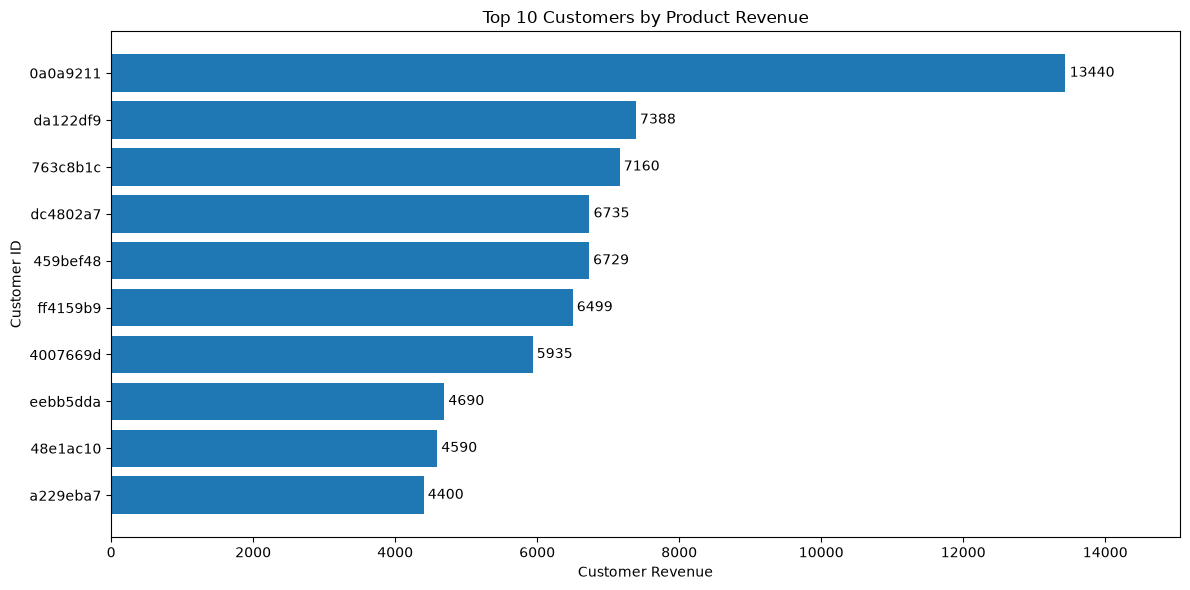

In [143]:
import matplotlib.pyplot as plt

# 1. Select top 10 customers
top_10_customers = customer_revenue.head(10)

# 2. Create horizontal bar chart
plt.figure(figsize=(12, 6))

bars = plt.barh(
    top_10_customers['customer_unique_id'].str[:8],
    top_10_customers['customer_revenue']
)

# 3. Add title and axis labels
plt.title('Top 10 Customers by Product Revenue')
plt.xlabel('Customer Revenue')
plt.ylabel('Customer ID')

# 4. Put highest-revenue customer at the top
plt.gca().invert_yaxis()

# 5. Display revenue values on bars
plt.bar_label(bars, fmt='%.0f', padding=3)

# 6. Add extra space for revenue labels
plt.xlim(0, top_10_customers['customer_revenue'].max() * 1.12)

# 7. Display chart
plt.tight_layout()
plt.show()

In [144]:
print(customer_revenue.head(1))
print(customer_frequency.sort_values(
    by='total_orders', ascending=False
).head(1))

                 customer_unique_id  customer_revenue
0  0a0a92112bd4c708ca5fde585afaa872           13440.0
                     customer_unique_id  total_orders
51431  8d50f5eadf50201ccdcedfb9e2ac8455            15


In [145]:
delivered_customer_sales['order_purchase_timestamp'] = pd.to_datetime(
    delivered_customer_sales['order_purchase_timestamp']
)

delivered_customer_sales['year'] = (
    delivered_customer_sales['order_purchase_timestamp'].dt.year
)

delivered_customer_sales['month'] = (
    delivered_customer_sales['order_purchase_timestamp'].dt.month
)

monthly_revenue = (
    delivered_customer_sales
    .groupby(['year', 'month'])['product_revenue']
    .sum()
    .reset_index()
)

monthly_revenue['date'] = pd.to_datetime(
    monthly_revenue[['year', 'month']].assign(day=1)
)

monthly_revenue = monthly_revenue.sort_values(
    by='date'
)

monthly_revenue = monthly_revenue[
    ['date', 'product_revenue']
].reset_index(drop=True)

monthly_revenue.head()

,date,product_revenue
0,2016-09-01,134.97
1,2016-10-01,40325.11
2,2016-12-01,10.90
3,2017-01-01,111798.36
4,2017-02-01,234223.40


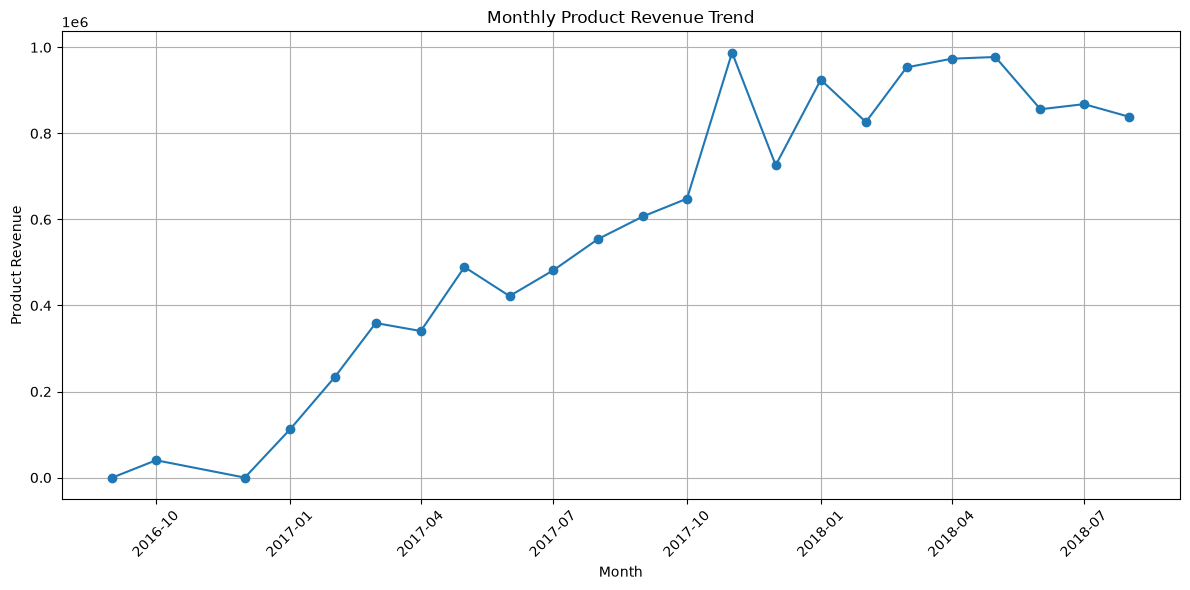

In [147]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['product_revenue'],
    marker='o'
)

plt.title('Monthly Product Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Product Revenue')

plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [149]:
max_revenue_month = monthly_revenue.loc[
    monthly_revenue['product_revenue'].idxmax()
]

min_revenue_month = monthly_revenue.loc[
    monthly_revenue['product_revenue'].idxmin()
]

print("Highest Renvenue Month:")
print("Date:", max_revenue_month['date'])
print("Revenue:", max_revenue_month['product_revenue'])

print("\nLowest Revenue Month:")
print("Date:", min_revenue_month['date'])
print("Revenue:", min_revenue_month['product_revenue'])

Highest Renvenue Month:
Date: 2017-11-01 00:00:00
Revenue: 987765.37

Lowest Revenue Month:
Date: 2016-12-01 00:00:00
Revenue: 10.9


In [151]:
monthly_revenue['revenue_growth_pct'] = (
    monthly_revenue['product_revenue'].pct_change() * 100
)

print(monthly_revenue[
    ['date', 'product_revenue', 'revenue_growth_pct']
]
)

         date  product_revenue  revenue_growth_pct
0  2016-09-01           134.97                 NaN
1  2016-10-01         40325.11        2.977709e+04
2  2016-12-01            10.90       -9.997297e+01
3  2017-01-01        111798.36        1.025573e+06
4  2017-02-01        234223.40        1.095052e+02
5  2017-03-01        359198.85        5.335737e+01
6  2017-04-01        340669.68       -5.158471e+00
7  2017-05-01        489338.25        4.364009e+01
8  2017-06-01        421923.37       -1.377674e+01
9  2017-07-01        481604.52        1.414502e+01
10 2017-08-01        554699.70        1.517743e+01
11 2017-09-01        607399.67        9.500631e+00
12 2017-10-01        648247.65        6.725058e+00
13 2017-11-01        987765.37        5.237469e+01
14 2017-12-01        726033.19       -2.649740e+01
15 2018-01-01        924645.00        2.735575e+01
16 2018-02-01        826437.13       -1.062114e+01
17 2018-03-01        953356.25        1.535738e+01
18 2018-04-01        973534.09 

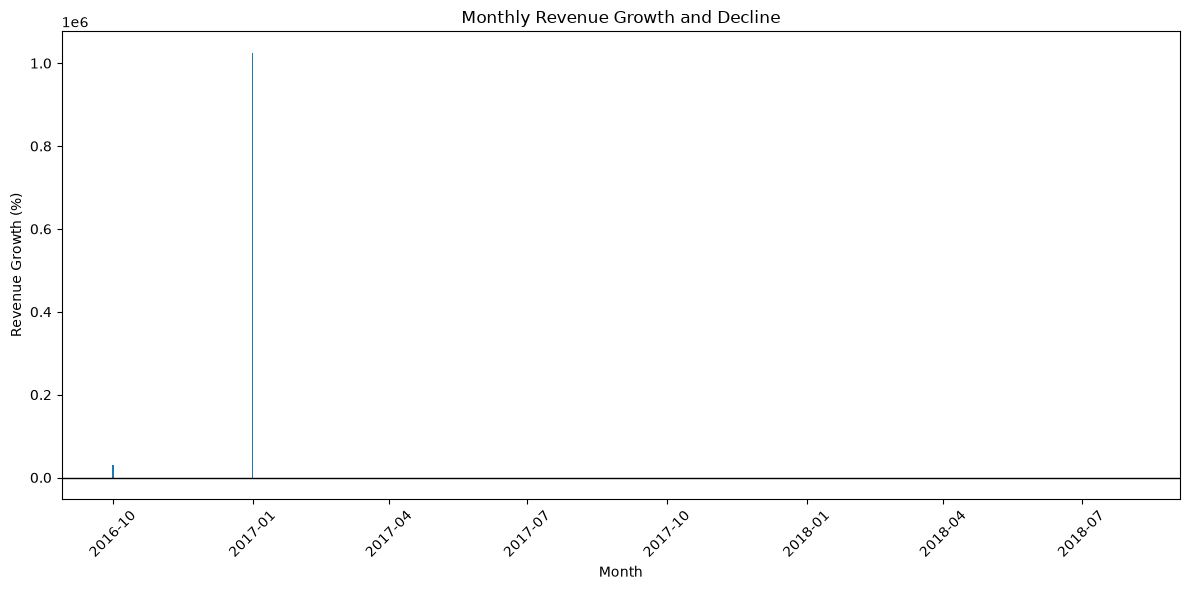

In [153]:
import matplotlib.pyplot as plt

monthly_revenue['revenue_growth_pct'] = (
    monthly_revenue['product_revenue'].pct_change() * 100
)

plt.figure(figsize = (12, 6))

bars = plt.bar(
    monthly_revenue['date'],
    monthly_revenue['revenue_growth_pct']
)

plt.axhline(y=0, color='black', linewidth=1)

plt.title('Monthly Revenue Growth and Decline')
plt.xlabel('Month')
plt.ylabel('Revenue Growth (%)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [154]:
monthly_revenue['moving_avg_3_month'] = (
    monthly_revenue['product_revenue']
    .rolling(window=3)
    .mean()
)

# 2. Display required columns
monthly_revenue[
    ['date', 'product_revenue', 'moving_avg_3_month']
]

,date,product_revenue,moving_avg_3_month
0,2016-09-01,134.97,NaN
1,2016-10-01,40325.11,NaN
2,2016-12-01,10.90,13490.326667
3,2017-01-01,111798.36,50711.456667
4,2017-02-01,234223.40,115344.220000
5,2017-03-01,359198.85,235073.536667
6,2017-04-01,340669.68,311363.976667
7,2017-05-01,489338.25,396402.260000
8,2017-06-01,421923.37,417310.433333
9,2017-07-01,481604.52,464288.713333


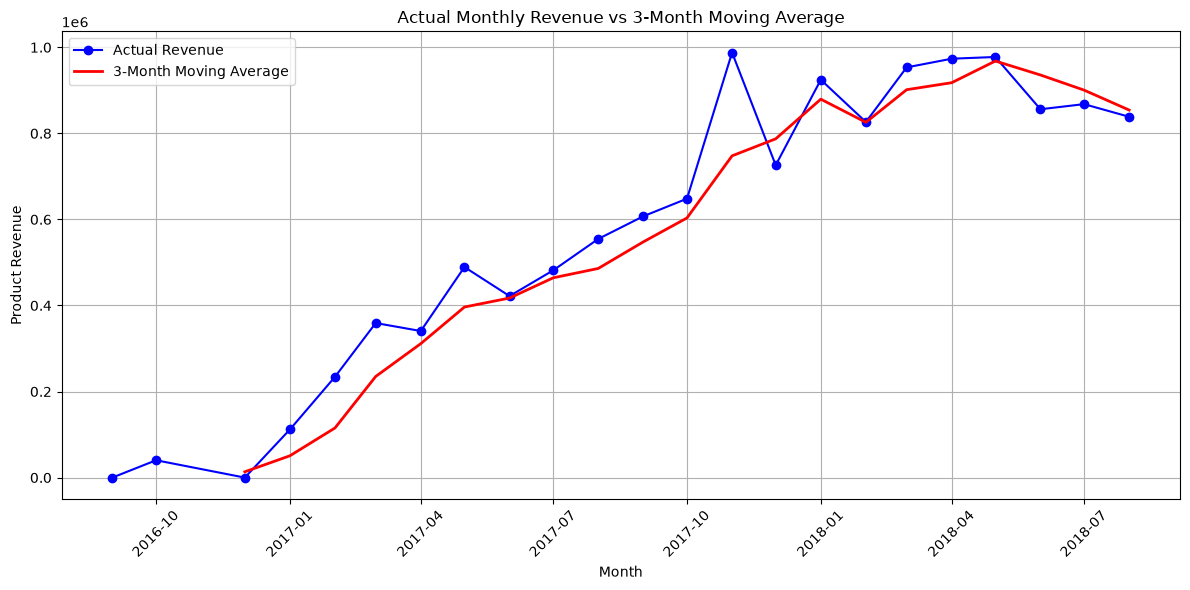

In [155]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['product_revenue'],
    color='blue',
    marker='o',
    label='Actual Revenue'
)

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['moving_avg_3_month'],
    color='red',
    linewidth=2,
    label='3-Month Moving Average'
)

plt.title('Actual Monthly Revenue vs 3-Month Moving Average')
plt.xlabel('Month')
plt.ylabel('Product Revenue')

plt.xticks(rotation=45)

plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()

In [156]:
forecast_data = monthly_revenue [
    ~(
        ((monthly_revenue['date'].dt.year == 2016) &
         (monthly_revenue['date'].dt.month == 9)) |
         ((monthly_revenue['date'].dt.year == 2018) &
          (monthly_revenue['date'].dt.month == 10))
    )
]

forecast_data = forecast_data[
    ['date', 'product_revenue']
]

forecast_data = forecast_data.reset_index(drop=True)

display(forecast_data.head())

display(forecast_data.tail())

,date,product_revenue
0,2016-10-01,40325.11
1,2016-12-01,10.90
2,2017-01-01,111798.36
3,2017-02-01,234223.40
4,2017-03-01,359198.85


,date,product_revenue
17,2018-04-01,973534.09
18,2018-05-01,977544.69
19,2018-06-01,856077.86
20,2018-07-01,867953.46
21,2018-08-01,838576.64


In [157]:
split_index = int(len(forecast_data)*0.8)

train_data = forecast_data.iloc[:split_index]

test_data = forecast_data.iloc[split_index:]

print("Trainend data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

print("Last training date:", train_data['date'].iloc[-1])
print("First training date:", test_data['date'].iloc[0])

Trainend data shape: (17, 2)
Testing data shape: (5, 2)
Last training date: 2018-03-01 00:00:00
First training date: 2018-04-01 00:00:00


In [158]:
total_rows = len(forecast_data)

train_percentage = (len(train_data)/total_rows)*100
test_percentage = (len(test_data)/total_rows)*100

print("Training percentage:", round(train_percentage, 2), "%")
print("Testing percentage:", round(test_percentage, 2), "%")

print("\nTraining dates in chronological order:",
      train_data['date'].is_monotonic_increasing)

print("Testing dates in chronological order:",
      test_data['date'].is_monotonic_increasing) 

print("\nLast training date:", train_data['date'].iloc[-1])
print("First testing date:", test_data['date'].iloc[0])

print("Training date is earlier than testing date:",
      train_data['date'].iloc[-1] < test_data['date'].iloc[0])

print("\nMissing values in training data:")
print(train_data.isnull().sum())

print("\nMissing values in testing data:")
print(test_data.isnull().sum())


Training percentage: 77.27 %
Testing percentage: 22.73 %

Training dates in chronological order: True
Testing dates in chronological order: True

Last training date: 2018-03-01 00:00:00
First testing date: 2018-04-01 00:00:00
Training date is earlier than testing date: True

Missing values in training data:
date               0
product_revenue    0
dtype: int64

Missing values in testing data:
date               0
product_revenue    0
dtype: int64


In [159]:
customer_orders = (
    delivered_customer_sales.groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index()
)

customer_orders = customer_orders.rename(
    columns={
        'order_id':'total_orders'
    }
)

display(customer_orders)
print("Customer orders shape:", customer_orders.shape)

,customer_unique_id,total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1
...,...,...
93353,fffcf5a5ff07b0908bd4e2dbc735a684,1
93354,fffea47cd6d3cc0a88bd621562a9d061,1
93355,ffff371b4d645b6ecea244b27531430a,1
93356,ffff5962728ec6157033ef9805bacc48,1


Customer orders shape: (93358, 2)


In [162]:
one_time_customers = customer_orders[
    customer_orders['total_orders'] == 1
]

repeat_customers = customer_orders[
    customer_orders['total_orders'] > 1
]

print("Total one-time customers:", one_time_customers.shape[0])
print("Total repeat customers:", repeat_customers.shape[0])

total_customers = customer_orders.shape[0]

repeat_percentage = (
    repeat_customers.shape[0] / total_customers
) * 100

print("Repeat customer percentage:", round(repeat_percentage, 2), "%")

Total one-time customers: 90557
Total repeat customers: 2801
Repeat customer percentage: 3.0 %


In [163]:
customer_last_purchase  = (
    delivered_customer_sales
    .groupby('customer_unique_id')['order_purchase_timestamp']
    .max()
    .reset_index()
)

customer_last_purchase = customer_last_purchase.rename(
    columns={
        'order_purchase_timestamp': 'last_purchase_date'
    }
)

display(customer_last_purchase.head())

print("DataFrame Shape:", customer_last_purchase.shape)

,customer_unique_id,last_purchase_date
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42


DataFrame Shape: (93358, 2)


In [164]:
snapshot_date = delivered_customer_sales['order_purchase_timestamp'].max()

customer_last_purchase['days_since_last_purchase'] = (
    snapshot_date - customer_last_purchase['last_purchase_date']
).dt.days

display(customer_last_purchase.head())

,customer_unique_id,last_purchase_date,days_since_last_purchase
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,111
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,114
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,536
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,320
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,287


In [166]:
import numpy as np

customer_last_purchase['churn'] = np.where(
    customer_last_purchase['days_since_last_purchase'] <= 90,0,1
)

display(customer_last_purchase.head())

print("\nCustomer Churn Distribution:")
print(customer_last_purchase['churn'].value_counts())

,customer_unique_id,last_purchase_date,days_since_last_purchase,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,111,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,114,1
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,536,1
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,320,1
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,287,1



Customer Churn Distribution:
churn
1    74768
0    18590
Name: count, dtype: int64


In [169]:
total_customers = customer_last_purchase.shape[0]

total_active_customers = customer_last_purchase[customer_last_purchase['churn'] == 0].shape[0]

total_churned_customers = customer_last_purchase[customer_last_purchase['churn'] == 1].shape[0]

churn_percentage = (
    (total_churned_customers)/(total_customers)*100
)

active_percentage = (
    (total_active_customers)/(total_customers)*100
)

print("Total Customers:", total_customers)
print("Active Customers:", total_active_customers)
print("Churned Customers:", total_churned_customers)
print("\nPercentage of churned customers", round(churn_percentage,2), "%")
print("\nPercentage of active customers",round(active_percentage,2), "%")

Total Customers: 93358
Active Customers: 18590
Churned Customers: 74768

Percentage of churned customers 80.09 %

Percentage of active customers 19.91 %


In [170]:
customer_churn_data = customer_orders.merge(
    customer_last_purchase,
    on='customer_unique_id',
    how='inner'
)

display(customer_churn_data.head())

print("Shape:", customer_churn_data.shape)

print("\nMissing Values:")
print(customer_churn_data.isnull().sum())

,customer_unique_id,total_orders,last_purchase_date,days_since_last_purchase,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,1,2018-05-10 10:56:27,111,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,2018-05-07 11:11:27,114,1
2,0000f46a3911fa3c0805444483337064,1,2017-03-10 21:05:03,536,1
3,0000f6ccb0745a6a4b88665a16c9f078,1,2017-10-12 20:29:41,320,1
4,0004aac84e0df4da2b147fca70cf8255,1,2017-11-14 19:45:42,287,1


Shape: (93358, 5)

Missing Values:
customer_unique_id          0
total_orders                0
last_purchase_date          0
days_since_last_purchase    0
churn                       0
dtype: int64


In [174]:
customer_revenue = (
    delivered_customer_sales
    .groupby('customer_unique_id')['product_revenue']
    .sum()
    .reset_index()
    .rename(columns={'product_revenue': 'total_revenue'})
)

display(customer_revenue.head())

print("Shape:", customer_revenue.shape)

,customer_unique_id,total_revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00


Shape: (93358, 2)


In [177]:
customer_churn_data = customer_churn_data.merge(
    customer_revenue,
    on='customer_unique_id',
    how='left'
)

display(customer_churn_data.head())

print(customer_churn_data.shape)

print("\nMissing Values:")
print(customer_churn_data.isnull().sum())

print("\nFinal Columns:")
print(customer_churn_data.columns)



,customer_unique_id,total_orders,last_purchase_date,days_since_last_purchase,churn,total_revenue_x,total_revenue_y,total_revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,1,2018-05-10 10:56:27,111,1,129.90,129.90,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,2018-05-07 11:11:27,114,1,18.90,18.90,18.90
2,0000f46a3911fa3c0805444483337064,1,2017-03-10 21:05:03,536,1,69.00,69.00,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,2017-10-12 20:29:41,320,1,25.99,25.99,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,2017-11-14 19:45:42,287,1,180.00,180.00,180.00


(93358, 8)

Missing Values:
customer_unique_id          0
total_orders                0
last_purchase_date          0
days_since_last_purchase    0
churn                       0
total_revenue_x             0
total_revenue_y             0
total_revenue               0
dtype: int64

Final Columns:
Index(['customer_unique_id', 'total_orders', 'last_purchase_date',
       'days_since_last_purchase', 'churn', 'total_revenue_x',
       'total_revenue_y', 'total_revenue'],
      dtype='str')


In [180]:
feature_cutoff = pd.Timestamp('2018-07-01')
prediction_end = feature_cutoff + pd.Timedelta(days=90)

print("Feature Cutoff:", feature_cutoff)
print("Prediction End:", prediction_end)

print("Days Between:", (prediction_end - feature_cutoff).days)

Feature Cutoff: 2018-07-01 00:00:00
Prediction End: 2018-09-29 00:00:00
Days Between: 90


In [181]:
feature_data = delivered_customer_sales[
    delivered_customer_sales['order_purchase_timestamp'] < feature_cutoff
].copy()

display(feature_data.head())

print("Shape:", feature_data.shape)

print(
    "Maximum Purchase TimeStamp:",
    feature_data['order_purchase_timestamp'].max()
)

,order_id,customer_id,customer_unique_id,order_purchase_timestamp,product_revenue,total_freight,year,month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,29.99,8.72,2017,10
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,45.00,27.20,2017,11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,19.90,8.72,2018,2
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,80bb27c7c16e8f973207a5086ab329e2,2017-07-09 21:57:05,147.90,27.36,2017,7
6,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,932afa1e708222e5821dac9cd5db4cae,2017-05-16 13:10:30,59.99,15.17,2017,5


Shape: (83968, 8)
Maximum Purchase TimeStamp: 2018-06-30 23:59:49


In [182]:
prediction_data = delivered_customer_sales[
    (delivered_customer_sales['order_purchase_timestamp'] >= feature_cutoff) &
    (delivered_customer_sales['order_purchase_timestamp'] < prediction_end)
].copy()

display(prediction_data.head())

print("Shape:", prediction_data.shape)

print("Minimum Purchase Timestamp:",
      prediction_data['order_purchase_timestamp'].min())

print("Maximum Purchase Timestamp:",
      prediction_data['order_purchase_timestamp'].max())

,order_id,customer_id,customer_unique_id,order_purchase_timestamp,product_revenue,total_freight,year,month
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,118.7,22.76,2018,7
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,159.9,19.22,2018,8
12,5ff96c15d0b717ac6ad1f3d77225a350,19402a48fe860416adf93348aba37740,e2dfa3127fedbbca9707b36304996dab,2018-07-25 17:44:10,19.9,12.80,2018,7
23,f3e7c359154d965827355f39d6b1fdac,62b423aab58096ca514ba6aa06be2f98,9c9242ad7f1b52d926ea76778e1c0c57,2018-08-09 11:44:40,89.9,14.21,2018,8
33,b276e4f8c0fb86bd82fce576f21713e0,cf8ffeddf027932e51e4eae73b384059,6cbe8a392b76916e84c2faf69d0d0da0,2018-07-29 23:34:51,179.0,9.41,2018,7


Shape: (12510, 8)
Minimum Purchase Timestamp: 2018-07-01 00:25:07
Maximum Purchase Timestamp: 2018-08-29 15:00:37


In [183]:
feature_customer_orders = (
    feature_data
    .groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index()
    .rename(columns={'order_id': 'feature_total_orders'})
    )

display(feature_customer_orders.head())
print("Shape:", feature_customer_orders.shape)

,customer_unique_id,feature_total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


Shape: (81265, 2)


In [184]:
feature_customer_revenue = (
    feature_data
    .groupby('customer_unique_id')['product_revenue']
    .sum()
    .reset_index()
    .rename(columns={'product_revenue': 'feature_total_revenue'})
)

display(feature_customer_revenue.head())
print("Shape:", feature_customer_revenue.shape)

,customer_unique_id,feature_total_revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00


Shape: (81265, 2)


In [187]:
feature_customer_recency = (
    feature_data
    .groupby('customer_unique_id')['order_purchase_timestamp']
    .max()
    .reset_index()
    .rename(columns={'order_purchase_timestamp': 'feature_last_purchase_date'})
)

feature_customer_recency['feature_days_since_last_purchase'] = (
    feature_cutoff - feature_customer_recency['feature_last_purchase_date']
).dt.days

display(feature_customer_recency.head())

print("Shape:", feature_customer_recency.shape)

,customer_unique_id,feature_last_purchase_date,feature_days_since_last_purchase
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,51
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,54
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,477
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,261
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,228


Shape: (81265, 3)


In [188]:
prediction_customer_orders = (
    prediction_data
    .groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index()
    .rename(columns={'order_id': 'prediction_total_orders'})
)

display(prediction_customer_orders.head())
print("Shape:", prediction_customer_orders.shape)

,customer_unique_id,prediction_total_orders
0,000ec5bff359e1c0ad76a81a45cb598f,1
1,000fbf0473c10fc1ab6f8d2d286ce20c,1
2,0015752e079902b12cd00b9b7596276b,1
3,00172711b30d52eea8b313a7f2cced02,1
4,001928b561575b2821c92254a2327d06,1


Shape: (12373, 2)


In [189]:
feature_customer_churn = feature_customer_orders.merge(
    prediction_customer_orders,
    on='customer_unique_id',
    how='left'
)

feature_customer_churn['prediction_total_orders'] = (
    feature_customer_churn['prediction_total_orders'].fillna(0)
)

feature_customer_churn['prediction_total_orders'] = (
    feature_customer_churn['prediction_total_orders'].astype(int)
)

feature_customer_churn['churn'] = np.where(
    feature_customer_churn['prediction_total_orders'] == 0,
    1,
    0
)

display(feature_customer_churn.head())

print("Churn Distribution:")
print(feature_customer_churn['churn'].value_counts())


,customer_unique_id,feature_total_orders,prediction_total_orders,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,1,0,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,0,1
2,0000f46a3911fa3c0805444483337064,1,0,1
3,0000f6ccb0745a6a4b88665a16c9f078,1,0,1
4,0004aac84e0df4da2b147fca70cf8255,1,0,1


Churn Distribution:
churn
1    80985
0      280
Name: count, dtype: int64


In [ ]:
final_churn_data = feature_customer_churn.merge(
    feature_customer_recency,
    on='customer_unique_id',
    how='left'
)

final_churn_data = final_churn_data.merge(
    feature_customer_revenue,
    on='customer_unique_id',
    how='left'
)

display(final_churn_data.head())

print("Shape:", final_churn_data.shape)

print("\nMissing Values:")
print(final_churn_data.isnull().sum())

print("\nChurn Distribution:")
print(final_churn_data['churn'].value_counts())

,customer_unique_id,feature_total_orders,prediction_total_orders,churn,feature_last_purchase_date,feature_days_since_last_purchase,feature_total_revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,1,0,1,2018-05-10 10:56:27,51,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,0,1,2018-05-07 11:11:27,54,18.90
2,0000f46a3911fa3c0805444483337064,1,0,1,2017-03-10 21:05:03,477,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,0,1,2017-10-12 20:29:41,261,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,0,1,2017-11-14 19:45:42,228,180.00


Shape: (81265, 7)

Missing Values:
customer_unique_id                  0
feature_total_orders                0
prediction_total_orders             0
churn                               0
feature_last_purchase_date          0
feature_days_since_last_purchase    0
feature_total_revenue               0
dtype: int64

Churn Distribution:
churn
1    80985
0      280
Name: count, dtype: int64


In [191]:
print(final_churn_data.shape)
print(final_churn_data.isnull().sum())
print(final_churn_data['churn'].value_counts(normalize=True) * 100)

(81265, 7)
customer_unique_id                  0
feature_total_orders                0
prediction_total_orders             0
churn                               0
feature_last_purchase_date          0
feature_days_since_last_purchase    0
feature_total_revenue               0
dtype: int64
churn
1    99.655448
0     0.344552
Name: proportion, dtype: float64


In [192]:
print("Prediction window customers:",
      prediction_customer_orders['customer_unique_id'].nunique())

print("Feature window customers:",
      feature_customer_orders['customer_unique_id'].nunique())

print("\nChurn counts:")
print(final_churn_data['churn'].value_counts())

print("\nChurn percentages:")
print(
    final_churn_data['churn']
    .value_counts(normalize=True) * 100
)

Prediction window customers: 12373
Feature window customers: 81265

Churn counts:
churn
1    80985
0      280
Name: count, dtype: int64

Churn percentages:
churn
1    99.655448
0     0.344552
Name: proportion, dtype: float64


In [194]:
existing_customers = prediction_customer_orders[
    prediction_customer_orders['customer_unique_id'].isin(
        feature_customer_orders['customer_unique_id']
    )
]

new_customers = prediction_customer_orders[
    ~prediction_customer_orders['customer_unique_id'].isin(
        feature_customer_orders['customer_unique_id']
    )
]

print("Existing customers:", existing_customers.shape[0])
print("New customers:", new_customers.shape[0])
print("Total prediction customers:", prediction_customer_orders.shape[0])

Existing customers: 280
New customers: 12093
Total prediction customers: 12373


In [195]:
# 1. Convert timestamp to datetime if not already converted
orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

# 2. Filter orders within the prediction window
prediction_orders_all = orders[
    (orders['order_purchase_timestamp'] >= feature_cutoff) &
    (orders['order_purchase_timestamp'] < prediction_end)
].copy()

# 3. Display first five rows
display(prediction_orders_all.head())

# 4. Display shape
print("Shape:", prediction_orders_all.shape)

# 5. Count order statuses
print("\nOrder Status Distribution:")
print(prediction_orders_all['order_status'].value_counts())

# 6. Join with customers to get customer_unique_id
prediction_orders_all = prediction_orders_all.merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# 7. Count unique customers
print("\nUnique Customers:",
      prediction_orders_all['customer_unique_id'].nunique())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
13,5ff96c15d0b717ac6ad1f3d77225a350,19402a48fe860416adf93348aba37740,delivered,2018-07-25 17:44:10,2018-07-25 17:55:14,2018-07-26 13:16:00,2018-07-30 15:52:25,2018-08-08 00:00:00
24,f3e7c359154d965827355f39d6b1fdac,62b423aab58096ca514ba6aa06be2f98,delivered,2018-08-09 11:44:40,2018-08-10 03:24:51,2018-08-10 12:29:00,2018-08-13 18:24:27,2018-08-17 00:00:00
34,b276e4f8c0fb86bd82fce576f21713e0,cf8ffeddf027932e51e4eae73b384059,delivered,2018-07-29 23:34:51,2018-07-29 23:45:15,2018-07-30 14:43:00,2018-07-31 22:48:50,2018-08-06 00:00:00


Shape: (12819, 8)

Order Status Distribution:
order_status
delivered      12510
canceled         139
shipped          108
invoiced          36
unavailable       25
processing         1
Name: count, dtype: int64

Unique Customers: 12644


In [196]:
print(prediction_orders_all.shape)
print(prediction_orders_all['order_status'].value_counts())
print(prediction_orders_all['customer_unique_id'].nunique())

(12819, 9)
order_status
delivered      12510
canceled         139
shipped          108
invoiced          36
unavailable       25
processing         1
Name: count, dtype: int64
12644


In [197]:
prediction_customer_activity = (
    prediction_orders_all
    .groupby('customer_unique_id')['order_id']
    .nunique()
    .reset_index()
    .rename(columns={'order_id': 'prediction_total_orders'})
)

# Display first five rows
display(prediction_customer_activity.head())

# Display shape
print("Shape:", prediction_customer_activity.shape)

,customer_unique_id,prediction_total_orders
0,000ec5bff359e1c0ad76a81a45cb598f,1
1,000fbf0473c10fc1ab6f8d2d286ce20c,1
2,0015752e079902b12cd00b9b7596276b,1
3,00172711b30d52eea8b313a7f2cced02,2
4,001928b561575b2821c92254a2327d06,1


Shape: (12644, 2)


In [198]:
# Unique customer IDs in each dataset
feature_ids = set(feature_customer_orders['customer_unique_id'])
prediction_ids = set(prediction_customer_activity['customer_unique_id'])

# Customers appearing in both windows
common_customers = feature_ids.intersection(prediction_ids)

# Customers appearing only in prediction window
new_customers = prediction_ids - feature_ids

# Customers appearing only in feature window
missing_from_prediction = feature_ids - prediction_ids

print("Feature Window Customers:", len(feature_ids))
print("Prediction Window Customers:", len(prediction_ids))
print("Common Customers:", len(common_customers))
print("New Customers:", len(new_customers))
print("Feature Customers Without Prediction Activity:", len(missing_from_prediction))

Feature Window Customers: 81265
Prediction Window Customers: 12644
Common Customers: 287
New Customers: 12357
Feature Customers Without Prediction Activity: 80978


In [199]:
# 1. Merge feature and prediction activity
corrected_churn_data = feature_customer_orders.merge(
    prediction_customer_activity,
    on='customer_unique_id',
    how='left'
)

# 2. Fill missing prediction orders with 0
corrected_churn_data['prediction_total_orders'] = (
    corrected_churn_data['prediction_total_orders'].fillna(0)
)

# 3. Convert prediction orders to integer
corrected_churn_data['prediction_total_orders'] = (
    corrected_churn_data['prediction_total_orders'].astype(int)
)

# 4. Create churn label
corrected_churn_data['churn'] = np.where(
    corrected_churn_data['prediction_total_orders'] == 0,
    1,
    0
)

# 5. Display first five rows
display(corrected_churn_data.head())

# 6. Display churn distribution
print("Churn Distribution:")
print(corrected_churn_data['churn'].value_counts())

# 7. Display churn percentages
print("\nChurn Percentage:")
print(corrected_churn_data['churn'].value_counts(normalize=True) * 100)

,customer_unique_id,feature_total_orders,prediction_total_orders,churn
0,0000366f3b9a7992bf8c76cfdf3221e2,1,0,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,0,1
2,0000f46a3911fa3c0805444483337064,1,0,1
3,0000f6ccb0745a6a4b88665a16c9f078,1,0,1
4,0004aac84e0df4da2b147fca70cf8255,1,0,1


Churn Distribution:
churn
1    80978
0      287
Name: count, dtype: int64

Churn Percentage:
churn
1    99.646834
0     0.353166
Name: proportion, dtype: float64


In [200]:
print("Corrected dataset shape:", corrected_churn_data.shape)

print("\nChurn distribution:")
print(corrected_churn_data['churn'].value_counts())

print("\nChurn percentages:")
print(
    corrected_churn_data['churn']
    .value_counts(normalize=True) * 100
)

Corrected dataset shape: (81265, 4)

Churn distribution:
churn
1    80978
0      287
Name: count, dtype: int64

Churn percentages:
churn
1    99.646834
0     0.353166
Name: proportion, dtype: float64


In [201]:
# 1. Merge corrected churn data with customer recency
final_churn_data = corrected_churn_data.merge(
    feature_customer_recency,
    on='customer_unique_id',
    how='left'
)

# 2. Merge customer revenue
final_churn_data = final_churn_data.merge(
    feature_customer_revenue,
    on='customer_unique_id',
    how='left'
)

# 3. Display first five rows
display(final_churn_data.head())

# 4. Display shape
print("Shape:", final_churn_data.shape)

# 5. Check missing values
print("\nMissing Values:")
print(final_churn_data.isnull().sum())

# 6. Display churn distribution
print("\nChurn Distribution:")
print(final_churn_data['churn'].value_counts())

# 7. Display churn percentages
print("\nChurn Percentages:")
print(final_churn_data['churn'].value_counts(normalize=True) * 100)

,customer_unique_id,feature_total_orders,prediction_total_orders,churn,feature_last_purchase_date,feature_days_since_last_purchase,feature_total_revenue
0,0000366f3b9a7992bf8c76cfdf3221e2,1,0,1,2018-05-10 10:56:27,51,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,0,1,2018-05-07 11:11:27,54,18.90
2,0000f46a3911fa3c0805444483337064,1,0,1,2017-03-10 21:05:03,477,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,1,0,1,2017-10-12 20:29:41,261,25.99
4,0004aac84e0df4da2b147fca70cf8255,1,0,1,2017-11-14 19:45:42,228,180.00


Shape: (81265, 7)

Missing Values:
customer_unique_id                  0
feature_total_orders                0
prediction_total_orders             0
churn                               0
feature_last_purchase_date          0
feature_days_since_last_purchase    0
feature_total_revenue               0
dtype: int64

Churn Distribution:
churn
1    80978
0      287
Name: count, dtype: int64

Churn Percentages:
churn
1    99.646834
0     0.353166
Name: proportion, dtype: float64


In [202]:
print("Shape:", final_churn_data.shape)
print("\nMissing values:")
print(final_churn_data.isnull().sum())

print("\nChurn distribution:")
print(final_churn_data['churn'].value_counts())

Shape: (81265, 7)

Missing values:
customer_unique_id                  0
feature_total_orders                0
prediction_total_orders             0
churn                               0
feature_last_purchase_date          0
feature_days_since_last_purchase    0
feature_total_revenue               0
dtype: int64

Churn distribution:
churn
1    80978
0      287
Name: count, dtype: int64


In [203]:
X = final_churn_data[
    [
        'feature_total_orders',
        'feature_days_since_last_purchase',
        'feature_total_revenue'
    ]
]

y = final_churn_data['churn']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

display(X.head())

X Shape: (81265, 3)
y Shape: (81265,)


,feature_total_orders,feature_days_since_last_purchase,feature_total_revenue
0,1,51,129.90
1,1,54,18.90
2,1,477,69.00
3,1,261,25.99
4,1,228,180.00


In [204]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (65012, 3)
X_test: (16253, 3)
y_train: (65012,)
y_test: (16253,)


In [205]:
print("Training distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
churn
1    64782
0      230
Name: count, dtype: int64
churn
1    99.646219
0     0.353781
Name: proportion, dtype: float64

Testing distribution:
churn
1    16196
0       57
Name: count, dtype: int64
churn
1    99.649296
0     0.350704
Name: proportion, dtype: float64


In [206]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create baseline model
dummy_model = DummyClassifier(strategy='most_frequent')

# Train model
dummy_model.fit(X_train, y_train)

# Make predictions
y_pred_dummy = dummy_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_dummy))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dummy))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dummy, zero_division=0))

Accuracy: 0.9964929551467422

Confusion Matrix:
[[    0    57]
 [    0 16196]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        57
           1       1.00      1.00      1.00     16196

    accuracy                           1.00     16253
   macro avg       0.50      0.50      0.50     16253
weighted avg       0.99      1.00      0.99     16253



In [207]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Create pipeline
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = logistic_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Accuracy: 0.5719559465944749

Confusion Matrix:
[[  28   29]
 [6928 9268]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.49      0.01        57
           1       1.00      0.57      0.73     16196

    accuracy                           0.57     16253
   macro avg       0.50      0.53      0.37     16253
weighted avg       0.99      0.57      0.72     16253



In [208]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Accuracy: 0.9942779794499477

Confusion Matrix:
[[    0    57]
 [   36 16160]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        57
           1       1.00      1.00      1.00     16196

    accuracy                           0.99     16253
   macro avg       0.50      0.50      0.50     16253
weighted avg       0.99      0.99      0.99     16253



In [209]:
from sklearn.metrics import balanced_accuracy_score, f1_score

models = {
    "Dummy Baseline": y_pred_dummy,
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf
}

for name, predictions in models.items():
    print(f"\n{name}")
    print("Balanced Accuracy:",
          balanced_accuracy_score(y_test, predictions))
    print("Macro F1:",
          f1_score(y_test, predictions, average='macro'))


Dummy Baseline
Balanced Accuracy: 0.5
Macro F1: 0.4991216986655983

Logistic Regression
Balanced Accuracy: 0.5317340647246667
Macro F1: 0.3675433638440346

Random Forest
Balanced Accuracy: 0.4988886144727093
Macro F1: 0.49856539042976583


In [210]:
from sklearn.metrics import average_precision_score

# Get probability predictions
y_prob_lr = logistic_model.predict_proba(X_test)

# Find probability column for class 0 (active)
active_index = list(logistic_model.classes_).index(0)
active_probabilities = y_prob_lr[:, active_index]

# Evaluate active-customer ranking
active_average_precision = average_precision_score(
    (y_test == 0).astype(int),
    active_probabilities
)

print("Active customer baseline prevalence:",
      (y_test == 0).mean())

print("Active customer Average Precision:",
      active_average_precision)


Active customer baseline prevalence: 0.00350704485325786
Active customer Average Precision: 0.008806343365288991


In [211]:
import pandas as pd

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.named_steps['model'].coef_[0]
})

coefficients['Absolute_Importance'] = (
    coefficients['Coefficient'].abs()
)

coefficients = coefficients.sort_values(
    by='Absolute_Importance',
    ascending=False
)

display(coefficients)

,Feature,Coefficient,Absolute_Importance
1,feature_days_since_last_purchase,0.331121,0.331121
0,feature_total_orders,-0.228172,0.228172
2,feature_total_revenue,0.121670,0.121670


In [212]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

final_model_comparison = pd.DataFrame({
    'Model': [
        'Dummy Baseline',
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred_dummy),
        balanced_accuracy_score(y_test, y_pred_lr),
        balanced_accuracy_score(y_test, y_pred_rf)
    ],
    'Macro F1': [
        f1_score(y_test, y_pred_dummy, average='macro'),
        f1_score(y_test, y_pred_lr, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro')
    ]
})

display(final_model_comparison)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Dummy Baseline,0.996493,0.500000,0.499122
1,Logistic Regression,0.571956,0.531734,0.367543
2,Random Forest,0.994278,0.498889,0.498565


In [213]:
print("FEATURE WINDOW")
print("Start:", feature_data['order_purchase_timestamp'].min())
print("End:", feature_data['order_purchase_timestamp'].max())
print("Unique customers:", feature_data['customer_unique_id'].nunique())
print("Unique orders:", feature_data['order_id'].nunique())

print("\nPREDICTION WINDOW")
print("Start:", prediction_orders_all['order_purchase_timestamp'].min())
print("End:", prediction_orders_all['order_purchase_timestamp'].max())
print("Unique customers:", prediction_orders_all['customer_unique_id'].nunique())
print("Unique orders:", prediction_orders_all['order_id'].nunique())

print("\nCHURN LABEL DISTRIBUTION")
print(final_churn_data['churn'].value_counts())
print(final_churn_data['churn'].value_counts(normalize=True) * 100)

FEATURE WINDOW
Start: 2016-09-15 12:16:38
End: 2018-06-30 23:59:49
Unique customers: 81265
Unique orders: 83968

PREDICTION WINDOW
Start: 2018-07-01 00:25:07
End: 2018-09-26 08:40:15
Unique customers: 12644
Unique orders: 12819

CHURN LABEL DISTRIBUTION
churn
1    80978
0      287
Name: count, dtype: int64
churn
1    99.646834
0     0.353166
Name: proportion, dtype: float64


In [214]:
print("Historical orders per customer:")
print(final_churn_data['feature_total_orders'].value_counts().sort_index())

print("\nPercentage of customers by order count:")
print(
    final_churn_data['feature_total_orders']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("\nCustomers with only one order:")
print(
    (final_churn_data['feature_total_orders'] == 1).sum()
)

print("\nCustomers with multiple orders:")
print(
    (final_churn_data['feature_total_orders'] > 1).sum()
)


Historical orders per customer:
feature_total_orders
1     78839
2      2227
3       158
4        23
5         9
6         4
7         3
9         1
10        1
Name: count, dtype: int64

Percentage of customers by order count:
feature_total_orders
1     97.014705
2      2.740417
3      0.194426
4      0.028302
5      0.011075
6      0.004922
7      0.003692
9      0.001231
10     0.001231
Name: proportion, dtype: float64

Customers with only one order:
78839

Customers with multiple orders:
2426


In [215]:
churn_by_frequency = (
    final_churn_data
    .groupby('feature_total_orders')
    .agg(
        total_customers=('customer_unique_id', 'count'),
        churned_customers=('churn', 'sum')
    )
)

churn_by_frequency['active_customers'] = (
    churn_by_frequency['total_customers']
    - churn_by_frequency['churned_customers']
)

churn_by_frequency['churn_rate_pct'] = (
    churn_by_frequency['churned_customers']
    / churn_by_frequency['total_customers'] * 100
)

churn_by_frequency['active_rate_pct'] = (
    churn_by_frequency['active_customers']
    / churn_by_frequency['total_customers'] * 100
)

display(churn_by_frequency)

,total_customers,churned_customers,active_customers,churn_rate_pct,active_rate_pct
feature_total_orders,,,,,
1,78839,78580,259,99.671482,0.328518
2,2227,2207,20,99.101931,0.898069
3,158,153,5,96.835443,3.164557
4,23,22,1,95.652174,4.347826
5,9,8,1,88.888889,11.111111
6,4,4,0,100.000000,0.000000
7,3,3,0,100.000000,0.000000
9,1,1,0,100.000000,0.000000
10,1,0,1,0.000000,100.000000


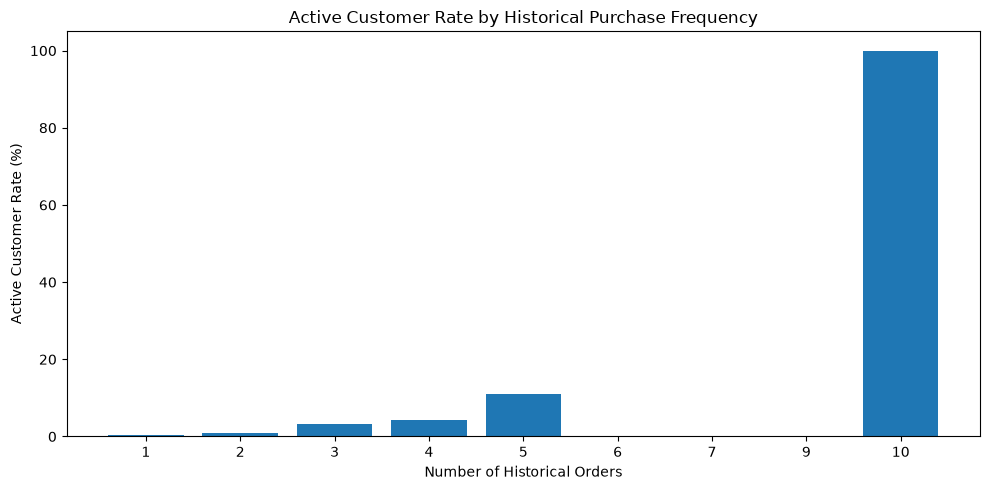

In [216]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    churn_by_frequency.index.astype(str),
    churn_by_frequency['active_rate_pct']
)

plt.title('Active Customer Rate by Historical Purchase Frequency')
plt.xlabel('Number of Historical Orders')
plt.ylabel('Active Customer Rate (%)')

plt.tight_layout()
plt.show()

In [217]:
feature_cutoff = pd.Timestamp('2018-07-01')
prediction_end_180 = feature_cutoff + pd.Timedelta(days=180)

prediction_orders_180 = orders[
    (orders['order_purchase_timestamp'] >= feature_cutoff) &
    (orders['order_purchase_timestamp'] < prediction_end_180)
].merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

activity_180 = (
    prediction_orders_180
    .groupby('customer_unique_id')['order_id']
    .nunique()
)

churn_180 = final_churn_data[
    ['customer_unique_id']
].copy()

churn_180['prediction_orders'] = (
    churn_180['customer_unique_id']
    .map(activity_180)
    .fillna(0)
)

churn_180['churn_180'] = (
    churn_180['prediction_orders'] == 0
).astype(int)

print("180-day churn distribution:")
print(churn_180['churn_180'].value_counts())

print("\nPercentages:")
print(churn_180['churn_180'].value_counts(normalize=True) * 100)

180-day churn distribution:
churn_180
1    80977
0      288
Name: count, dtype: int64

Percentages:
churn_180
1    99.645604
0     0.354396
Name: proportion, dtype: float64


In [218]:
dataset_end = orders['order_purchase_timestamp'].max()

actual_observation_days = (
    dataset_end - feature_cutoff
).days

missing_observation_days = (
    prediction_end_180 - dataset_end
).days

print("Feature cutoff:", feature_cutoff)
print("Dataset end:", dataset_end)
print("Required 180-day end:", prediction_end_180)

print("\nActual observation days:", actual_observation_days)
print("Missing observation days:", missing_observation_days)

Feature cutoff: 2018-07-01 00:00:00
Dataset end: 2018-10-17 17:30:18
Required 180-day end: 2018-12-28 00:00:00

Actual observation days: 108
Missing observation days: 71


In [219]:
prediction_end_30 = feature_cutoff + pd.Timedelta(days=30)

prediction_orders_30 = orders[
    (orders['order_purchase_timestamp'] >= feature_cutoff) &
    (orders['order_purchase_timestamp'] < prediction_end_30)
].merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

activity_30 = (
    prediction_orders_30
    .groupby('customer_unique_id')['order_id']
    .nunique()
)

churn_30 = final_churn_data[
    ['customer_unique_id']
].copy()

churn_30['prediction_orders'] = (
    churn_30['customer_unique_id']
    .map(activity_30)
    .fillna(0)
)

churn_30['churn_30'] = (
    churn_30['prediction_orders'] == 0
).astype(int)

print("30-day churn distribution:")
print(churn_30['churn_30'].value_counts())

print("\nPercentages:")
print(churn_30['churn_30'].value_counts(normalize=True) * 100)

30-day churn distribution:
churn_30
1    81117
0      148
Name: count, dtype: int64

Percentages:
churn_30
1    99.81788
0     0.18212
Name: proportion, dtype: float64


In [220]:
repeat_customer_data = final_churn_data[
    final_churn_data['feature_total_orders'] > 1
].copy()

print("Repeat customer cohort shape:",
      repeat_customer_data.shape)

print("\n90-day churn distribution:")
print(repeat_customer_data['churn'].value_counts())

print("\nPercentages:")
print(
    repeat_customer_data['churn']
    .value_counts(normalize=True) * 100
)

Repeat customer cohort shape: (2426, 7)

90-day churn distribution:
churn
1    2398
0      28
Name: count, dtype: int64

Percentages:
churn
1    98.845837
0     1.154163
Name: proportion, dtype: float64


In [221]:
repeat_customer_data['recency_group'] = pd.cut(
    repeat_customer_data['feature_days_since_last_purchase'],
    bins=[0, 30, 60, 90, 180, float('inf')],
    labels=['0-30 days', '31-60 days', '61-90 days',
            '91-180 days', '180+ days']
)

recency_analysis = (
    repeat_customer_data
    .groupby('recency_group', observed=False)
    .agg(
        total_customers=('customer_unique_id', 'count'),
        active_customers=('churn', lambda x: (x == 0).sum())
    )
)

recency_analysis['active_rate_pct'] = (
    recency_analysis['active_customers']
    / recency_analysis['total_customers'] * 100
)

display(recency_analysis)

,total_customers,active_customers,active_rate_pct
recency_group,,,
0-30 days,215,6,2.790698
31-60 days,226,3,1.327434
61-90 days,199,5,2.512563
91-180 days,656,4,0.609756
180+ days,1125,10,0.888889


In [222]:
repeat_customer_data['recency_group'] = pd.cut(
    repeat_customer_data['feature_days_since_last_purchase'],
    bins=[-1, 30, 60, 90, 180, float('inf')],
    labels=['0-30 days', '31-60 days', '61-90 days',
            '91-180 days', '180+ days']
)

recency_analysis = (
    repeat_customer_data
    .groupby('recency_group', observed=False)
    .agg(
        total_customers=('customer_unique_id', 'count'),
        active_customers=('churn', lambda x: (x == 0).sum())
    )
)

recency_analysis['active_rate_pct'] = (
    recency_analysis['active_customers']
    / recency_analysis['total_customers'] * 100
)

display(recency_analysis)

print("Total customers in groups:",
      recency_analysis['total_customers'].sum())


,total_customers,active_customers,active_rate_pct
recency_group,,,
0-30 days,220,6,2.727273
31-60 days,226,3,1.327434
61-90 days,199,5,2.512563
91-180 days,656,4,0.609756
180+ days,1125,10,0.888889


Total customers in groups: 2426


In [223]:
milestone_10_summary = pd.DataFrame({
    'Analysis': [
        '30-day inactivity',
        '90-day inactivity',
        '180-day inactivity',
        'One-time customers',
        'Repeat customers',
        'Repeat customer active rate'
    ],
    'Result': [
        '99.82% churn',
        '99.65% churn',
        'Invalid - incomplete observation',
        '97.01%',
        '2,426 customers',
        '1.15%'
    ],
    'Conclusion': [
        'Severe imbalance',
        'Severe imbalance',
        'Insufficient observation period',
        'Most customers purchased once',
        'Small repeat-customer cohort',
        'Only 28 returned customers'
    ]
})

display(milestone_10_summary)

,Analysis,Result,Conclusion
0,30-day inactivity,99.82% churn,Severe imbalance
1,90-day inactivity,99.65% churn,Severe imbalance
2,180-day inactivity,Invalid - incomplete observation,Insufficient observation period
3,One-time customers,97.01%,Most customers purchased once
4,Repeat customers,"2,426 customers",Small repeat-customer cohort
5,Repeat customer active rate,1.15%,Only 28 returned customers


In [224]:
# Define new cutoff and prediction window
feature_cutoff_new = pd.Timestamp('2018-04-01')

prediction_end_new = (
    feature_cutoff_new + pd.Timedelta(days=180)
)

# Check dataset coverage
dataset_end = orders['order_purchase_timestamp'].max()

actual_days = (dataset_end - feature_cutoff_new).days

print("New feature cutoff:", feature_cutoff_new)
print("180-day prediction end:", prediction_end_new)
print("Dataset end:", dataset_end)

print("\nRequired observation days: 180")
print("Available observation days:", actual_days)
print("Observation window fully covered:",
      dataset_end >= prediction_end_new)

New feature cutoff: 2018-04-01 00:00:00
180-day prediction end: 2018-09-28 00:00:00
Dataset end: 2018-10-17 17:30:18

Required observation days: 180
Available observation days: 199
Observation window fully covered: True


In [225]:
# Historical feature window
feature_data_new = delivered_customer_sales[
    delivered_customer_sales['order_purchase_timestamp']
    < feature_cutoff_new
].copy()

print("New feature dataset shape:", feature_data_new.shape)

print("\nDate range:")
print("Start:", feature_data_new['order_purchase_timestamp'].min())
print("End:", feature_data_new['order_purchase_timestamp'].max())

print("\nUnique customers:",
      feature_data_new['customer_unique_id'].nunique())

print("Unique orders:",
      feature_data_new['order_id'].nunique())

New feature dataset shape: (64322, 8)

Date range:
Start: 2016-09-15 12:16:38
End: 2018-03-31 23:54:10

Unique customers: 62299
Unique orders: 64322


In [226]:
# Historical order frequency
feature_orders_new = (
    feature_data_new
    .groupby('customer_unique_id')
    .agg(feature_total_orders=('order_id', 'nunique'))
    .reset_index()
)

# Historical revenue
feature_revenue_new = (
    feature_data_new
    .groupby('customer_unique_id')
    .agg(feature_total_revenue=('product_revenue', 'sum'))
    .reset_index()
)

# Last purchase date
feature_recency_new = (
    feature_data_new
    .groupby('customer_unique_id')
    .agg(
        feature_last_purchase_date=(
            'order_purchase_timestamp', 'max'
        )
    )
    .reset_index()
)

# Combine features
customer_features_new = feature_orders_new.merge(
    feature_revenue_new,
    on='customer_unique_id'
).merge(
    feature_recency_new,
    on='customer_unique_id'
)

# Calculate recency
customer_features_new['feature_days_since_last_purchase'] = (
    feature_cutoff_new -
    customer_features_new['feature_last_purchase_date']
).dt.days

print("New customer features shape:",
      customer_features_new.shape)

display(customer_features_new.head())

New customer features shape: (62299, 5)


,customer_unique_id,feature_total_orders,feature_total_revenue,feature_last_purchase_date,feature_days_since_last_purchase
0,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,386
1,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,170
2,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,137
3,00053a61a98854899e70ed204dd4bafe,1,382.00,2018-02-28 11:15:41,31
4,0005e1862207bf6ccc02e4228effd9a0,1,135.00,2017-03-04 23:32:12,392


In [227]:
# Define 180-day prediction window
prediction_data_new = orders[
    (orders['order_purchase_timestamp'] >= feature_cutoff_new) &
    (orders['order_purchase_timestamp'] < prediction_end_new)
].merge(
    customers[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

# Count orders per customer
prediction_activity_new = (
    prediction_data_new
    .groupby('customer_unique_id')
    .agg(
        prediction_total_orders=('order_id', 'nunique')
    )
    .reset_index()
)

print("Prediction dataset shape:",
      prediction_data_new.shape)

print("Customers with prediction activity:",
      prediction_activity_new['customer_unique_id'].nunique())

print("\nOrder status distribution:")
print(prediction_data_new['order_status'].value_counts())

display(prediction_activity_new.head())

Prediction dataset shape: (32798, 9)
Customers with prediction activity: 32253

Order status distribution:
order_status
delivered      32156
shipped          304
canceled         196
invoiced          77
unavailable       50
processing        15
Name: count, dtype: int64


,customer_unique_id,prediction_total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0004bd2a26a76fe21f786e4fbd80607f,1
3,00050ab1314c0e55a6ca13cf7181fecf,1
4,000949456b182f53c18b68d6babc79c1,1


In [228]:
# Merge historical customer cohort with prediction activity
churn_data_new = customer_features_new.merge(
    prediction_activity_new,
    on='customer_unique_id',
    how='left'
)

# Fill missing prediction orders
churn_data_new['prediction_total_orders'] = (
    churn_data_new['prediction_total_orders'].fillna(0)
)

churn_data_new['prediction_total_orders'] = (
    churn_data_new['prediction_total_orders'].astype(int)
)

# Create churn label
# 1 = No order during 180 days
# 0 = At least one order during 180 days
churn_data_new['churn'] = (
    churn_data_new['prediction_total_orders'] == 0
).astype(int)

print("New churn dataset shape:", churn_data_new.shape)

print("\nChurn distribution:")
print(churn_data_new['churn'].value_counts())

print("\nChurn percentages:")
print(churn_data_new['churn'].value_counts(normalize=True) * 100)

display(churn_data_new.head())

New churn dataset shape: (62299, 7)

Churn distribution:
churn
1    61688
0      611
Name: count, dtype: int64

Churn percentages:
churn
1    99.019246
0     0.980754
Name: proportion, dtype: float64


,customer_unique_id,feature_total_orders,feature_total_revenue,feature_last_purchase_date,feature_days_since_last_purchase,prediction_total_orders,churn
0,0000f46a3911fa3c0805444483337064,1,69.00,2017-03-10 21:05:03,386,0,1
1,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,2017-10-12 20:29:41,170,0,1
2,0004aac84e0df4da2b147fca70cf8255,1,180.00,2017-11-14 19:45:42,137,0,1
3,00053a61a98854899e70ed204dd4bafe,1,382.00,2018-02-28 11:15:41,31,0,1
4,0005e1862207bf6ccc02e4228effd9a0,1,135.00,2017-03-04 23:32:12,392,0,1


In [229]:
print("Historical orders per customer:")
print(
    churn_data_new['feature_total_orders']
    .value_counts()
    .sort_index()
)

print("\nPercentage distribution:")
print(
    churn_data_new['feature_total_orders']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nOne-time customers:",
      (churn_data_new['feature_total_orders'] == 1).sum())

print("Repeat customers:",
      (churn_data_new['feature_total_orders'] > 1).sum())

Historical orders per customer:
feature_total_orders
1    60470
2     1687
3      115
4       14
5        7
6        3
7        1
8        1
9        1
Name: count, dtype: int64

Percentage distribution:
feature_total_orders
1    97.064158
2     2.707909
3     0.184594
4     0.022472
5     0.011236
6     0.004815
7     0.001605
8     0.001605
9     0.001605
Name: proportion, dtype: float64

One-time customers: 60470
Repeat customers: 1829


In [230]:
churn_frequency_new = (
    churn_data_new
    .groupby('feature_total_orders')
    .agg(
        total_customers=('customer_unique_id', 'count'),
        churned_customers=('churn', 'sum')
    )
)

churn_frequency_new['active_customers'] = (
    churn_frequency_new['total_customers']
    - churn_frequency_new['churned_customers']
)

churn_frequency_new['churn_rate_pct'] = (
    churn_frequency_new['churned_customers']
    / churn_frequency_new['total_customers'] * 100
)

churn_frequency_new['active_rate_pct'] = (
    churn_frequency_new['active_customers']
    / churn_frequency_new['total_customers'] * 100
)

display(churn_frequency_new)

,total_customers,churned_customers,active_customers,churn_rate_pct,active_rate_pct
feature_total_orders,,,,,
1,60470,59921,549,99.092112,0.907888
2,1687,1645,42,97.510373,2.489627
3,115,103,12,89.565217,10.434783
4,14,11,3,78.571429,21.428571
5,7,4,3,57.142857,42.857143
6,3,2,1,66.666667,33.333333
7,1,1,0,100.000000,0.000000
8,1,0,1,0.000000,100.000000
9,1,1,0,100.000000,0.000000


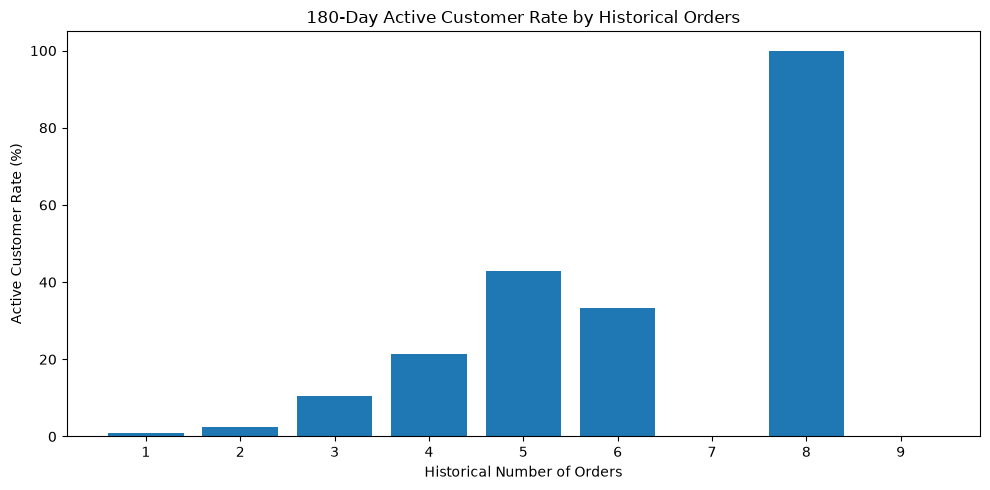

In [231]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    churn_frequency_new.index.astype(str),
    churn_frequency_new['active_rate_pct']
)

plt.title('180-Day Active Customer Rate by Historical Orders')
plt.xlabel('Historical Number of Orders')
plt.ylabel('Active Customer Rate (%)')

plt.tight_layout()
plt.show()

In [232]:
churn_data_new['recency_group'] = pd.cut(
    churn_data_new['feature_days_since_last_purchase'],
    bins=[-1, 30, 60, 90, 180, float('inf')],
    labels=['0-30 days', '31-60 days', '61-90 days',
            '91-180 days', '180+ days']
)

recency_analysis_new = (
    churn_data_new
    .groupby('recency_group', observed=False)
    .agg(
        total_customers=('customer_unique_id', 'count'),
        active_customers=('churn', lambda x: (x == 0).sum())
    )
)

recency_analysis_new['active_rate_pct'] = (
    recency_analysis_new['active_customers']
    / recency_analysis_new['total_customers'] * 100
)

display(recency_analysis_new)

print(
    "Total customers:",
    recency_analysis_new['total_customers'].sum()
)

,total_customers,active_customers,active_rate_pct
recency_group,,,
0-30 days,6913,91,1.316360
31-60 days,6864,97,1.413170
61-90 days,6504,77,1.183887
91-180 days,16640,146,0.877404
180+ days,25378,200,0.788084


Total customers: 62299


In [233]:
new_cohort_summary = pd.DataFrame({
    'Metric': [
        'Feature cutoff',
        'Prediction window',
        'Historical customers',
        'One-time customers',
        'Repeat customers',
        'Active customers',
        'Churned customers',
        'Churn percentage',
        'Active percentage'
    ],
    'Value': [
        '2018-04-01',
        '180 days',
        62299,
        60470,
        1829,
        611,
        61688,
        '99.02%',
        '0.98%'
    ]
})

display(new_cohort_summary)

,Metric,Value
0,Feature cutoff,2018-04-01
1,Prediction window,180 days
2,Historical customers,62299
3,One-time customers,60470
4,Repeat customers,1829
5,Active customers,611
6,Churned customers,61688
7,Churn percentage,99.02%
8,Active percentage,0.98%


In [234]:
# Select input features
X_new = churn_data_new[
    [
        'feature_total_orders',
        'feature_days_since_last_purchase',
        'feature_total_revenue'
    ]
]

# Select target
y_new = churn_data_new['churn']

# Verify
print("X Shape:", X_new.shape)
print("y Shape:", y_new.shape)

display(X_new.head())
display(y_new.head())

X Shape: (62299, 3)
y Shape: (62299,)


,feature_total_orders,feature_days_since_last_purchase,feature_total_revenue
0,1,386,69.00
1,1,170,25.99
2,1,137,180.00
3,1,31,382.00
4,1,392,135.00


0    1
1    1
2    1
3    1
4    1
Name: churn, dtype: int64

In [235]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new,
    y_new,
    test_size=0.20,
    random_state=42,
    stratify=y_new
)

print("X_train:", X_train_new.shape)
print("X_test:", X_test_new.shape)
print("y_train:", y_train_new.shape)
print("y_test:", y_test_new.shape)

X_train: (49839, 3)
X_test: (12460, 3)
y_train: (49839,)
y_test: (12460,)


In [236]:
print("Training distribution:")
print(y_train_new.value_counts())
print(y_train_new.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test_new.value_counts())
print(y_test_new.value_counts(normalize=True) * 100)

Training distribution:
churn
1    49350
0      489
Name: count, dtype: int64
churn
1    99.018841
0     0.981159
Name: proportion, dtype: float64

Testing distribution:
churn
1    12338
0      122
Name: count, dtype: int64
churn
1    99.020867
0     0.979133
Name: proportion, dtype: float64


In [237]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create baseline model
dummy_model_new = DummyClassifier(strategy='most_frequent')

# Train
dummy_model_new.fit(X_train_new, y_train_new)

# Predict
y_pred_dummy_new = dummy_model_new.predict(X_test_new)

# Evaluate
print("Accuracy:",
      accuracy_score(y_test_new, y_pred_dummy_new))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, y_pred_dummy_new))

print("\nClassification Report:")
print(classification_report(
    y_test_new,
    y_pred_dummy_new,
    zero_division=0
))


Accuracy: 0.9902086677367576

Confusion Matrix:
[[    0   122]
 [    0 12338]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       122
           1       0.99      1.00      1.00     12338

    accuracy                           0.99     12460
   macro avg       0.50      0.50      0.50     12460
weighted avg       0.98      0.99      0.99     12460



In [238]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create pipeline
logistic_model_new = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model_new.fit(X_train_new, y_train_new)

# Predict
y_pred_lr_new = logistic_model_new.predict(X_test_new)

# Evaluate
print("Accuracy:", accuracy_score(y_test_new, y_pred_lr_new))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, y_pred_lr_new))

print("\nClassification Report:")
print(classification_report(
    y_test_new,
    y_pred_lr_new,
    zero_division=0
))

Accuracy: 0.5774478330658106

Confusion Matrix:
[[  62   60]
 [5205 7133]]

Classification Report:
              precision    recall  f1-score   support

           0       0.01      0.51      0.02       122
           1       0.99      0.58      0.73     12338

    accuracy                           0.58     12460
   macro avg       0.50      0.54      0.38     12460
weighted avg       0.98      0.58      0.72     12460



In [239]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create model
rf_model_new = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

# Train
rf_model_new.fit(X_train_new, y_train_new)

# Predict
y_pred_rf_new = rf_model_new.predict(X_test_new)

# Evaluate
print("Accuracy:", accuracy_score(y_test_new, y_pred_rf_new))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, y_pred_rf_new))

print("\nClassification Report:")
print(classification_report(
    y_test_new,
    y_pred_rf_new,
    zero_division=0
))

Accuracy: 0.9830658105939005

Confusion Matrix:
[[    0   122]
 [   89 12249]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       122
           1       0.99      0.99      0.99     12338

    accuracy                           0.98     12460
   macro avg       0.50      0.50      0.50     12460
weighted avg       0.98      0.98      0.98     12460



In [240]:
from sklearn.metrics import balanced_accuracy_score, f1_score

models_new = {
    "Dummy Baseline": y_pred_dummy_new,
    "Logistic Regression": y_pred_lr_new,
    "Random Forest": y_pred_rf_new
}

for name, predictions in models_new.items():
    print(f"\n{name}")
    print(
        "Balanced Accuracy:",
        balanced_accuracy_score(y_test_new, predictions)
    )
    print(
        "Macro F1:",
        f1_score(y_test_new, predictions, average='macro')
    )


Dummy Baseline
Balanced Accuracy: 0.5
Macro F1: 0.4975401242035648

Logistic Regression
Balanced Accuracy: 0.5431646598938638
Macro F1: 0.3767191921670997

Random Forest
Balanced Accuracy: 0.4963932566056087
Macro F1: 0.49573030070014973


In [241]:
from sklearn.metrics import average_precision_score

# Get predicted probabilities
y_prob_lr_new = logistic_model_new.predict_proba(X_test_new)

# Locate class 0 (active customer)
active_index_new = list(
    logistic_model_new.classes_
).index(0)

active_probabilities_new = y_prob_lr_new[:, active_index_new]

# Calculate Average Precision
active_ap_new = average_precision_score(
    (y_test_new == 0).astype(int),
    active_probabilities_new
)

print(
    "Active customer baseline prevalence:",
    (y_test_new == 0).mean()
)

print("Active customer Average Precision:", active_ap_new)

Active customer baseline prevalence: 0.009791332263242376
Active customer Average Precision: 0.023946110363994022


In [242]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        active_probabilities_new >= threshold
    ).astype(int)

    # Convert back to original labels:
    # 1 = active, 0 = churn
    y_pred_threshold = 1 - y_pred_threshold

    threshold_results.append({
        'Threshold': threshold,
        'Active Precision': precision_score(
            y_test_new == 0,
            y_pred_threshold == 0,
            zero_division=0
        ),
        'Active Recall': recall_score(
            y_test_new == 0,
            y_pred_threshold == 0,
            zero_division=0
        ),
        'Active F1': f1_score(
            y_test_new == 0,
            y_pred_threshold == 0,
            zero_division=0
        )
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison)

,Threshold,Active Precision,Active Recall,Active F1
0,0.1,0.009793,1.000000,0.019396
1,0.2,0.009809,1.000000,0.019428
2,0.3,0.009877,1.000000,0.019561
3,0.4,0.010361,0.934426,0.020494
4,0.5,0.011771,0.508197,0.023010


In [244]:
from sklearn.dummy import DummyClassifier

dummy_model_new = DummyClassifier(strategy='most_frequent')

dummy_model_new.fit(X_train_new, y_train_new)

dummy_predictions_new = dummy_model_new.predict(X_test_new)

In [245]:
final_model_comparison = pd.DataFrame({
    'Model': [
        'Dummy Classifier',
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test_new, dummy_predictions_new),
        accuracy_score(y_test_new, logistic_model_new.predict(X_test_new)),
        accuracy_score(y_test_new, rf_model_new.predict(X_test_new))
    ],
    'Balanced Accuracy': [
        balanced_accuracy_score(y_test_new, dummy_predictions_new),
        balanced_accuracy_score(y_test_new, logistic_model_new.predict(X_test_new)),
        balanced_accuracy_score(y_test_new, rf_model_new.predict(X_test_new))
    ],
    'Macro F1': [
        f1_score(y_test_new, dummy_predictions_new, average='macro'),
        f1_score(y_test_new, logistic_model_new.predict(X_test_new), average='macro'),
        f1_score(y_test_new, rf_model_new.predict(X_test_new), average='macro')
    ]
})

display(final_model_comparison.round(4))

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Dummy Classifier,0.9902,0.5000,0.4975
1,Logistic Regression,0.5774,0.5432,0.3767
2,Random Forest,0.9831,0.4964,0.4957


In [246]:
business_insights = pd.DataFrame({
    'Business Area': [
        'Sales Performance',
        'Customer Retention',
        'Product Performance',
        'Customer Behaviour',
        'Churn Analysis',
        'Machine Learning'
    ],

    'Key Finding': [
        'November 2017 had the highest monthly revenue',
        'Repeat buyer rate was approximately 3%',
        'Health & Beauty was the top revenue category',
        'Approximately 97% of customers purchased only once',
        '99.02% had no observed purchase in the 180-day window',
        'Logistic Regression had the highest balanced accuracy'
    ]
})

display(business_insights)

,Business Area,Key Finding
0,Sales Performance,November 2017 had the highest monthly revenue
1,Customer Retention,Repeat buyer rate was approximately 3%
2,Product Performance,Health & Beauty was the top revenue category
3,Customer Behaviour,Approximately 97% of customers purchased only ...
4,Churn Analysis,99.02% had no observed purchase in the 180-day...
5,Machine Learning,Logistic Regression had the highest balanced a...


In [247]:
business_problems = pd.DataFrame({
    'Business Area': [
        'Sales Performance',
        'Customer Retention',
        'Product Performance',
        'Customer Behaviour',
        'Churn Analysis',
        'Machine Learning'
    ],

    'Business Problem': [
        'Sales revenue may fluctuate across different months',
        'Very few customers make repeat purchases',
        'Product categories may have unequal revenue contributions',
        'Most customers do not return after their first purchase',
        'Customer inactivity makes retention planning difficult',
        'Current models struggle to identify active customers reliably'
    ]
})

display(business_problems)

,Business Area,Business Problem
0,Sales Performance,Sales revenue may fluctuate across different m...
1,Customer Retention,Very few customers make repeat purchases
2,Product Performance,Product categories may have unequal revenue co...
3,Customer Behaviour,Most customers do not return after their first...
4,Churn Analysis,Customer inactivity makes retention planning d...
5,Machine Learning,Current models struggle to identify active cus...


In [248]:
business_recommendations = pd.DataFrame({
    'Business Area': [
        'Sales Performance',
        'Customer Retention',
        'Product Performance',
        'Customer Behaviour',
        'Churn Analysis',
        'Machine Learning'
    ],

    'Recommendation': [
        'Analyze seasonal sales trends and plan promotional campaigns',
        'Introduce loyalty programs and personalized offers',
        'Focus marketing efforts on high-revenue product categories',
        'Use personalized discounts to encourage second purchases',
        'Create targeted retention campaigns for inactive customers',
        'Improve model features and handle class imbalance before deployment'
    ]
})

display(business_recommendations)

,Business Area,Recommendation
0,Sales Performance,Analyze seasonal sales trends and plan promoti...
1,Customer Retention,Introduce loyalty programs and personalized of...
2,Product Performance,Focus marketing efforts on high-revenue produc...
3,Customer Behaviour,Use personalized discounts to encourage second...
4,Churn Analysis,Create targeted retention campaigns for inacti...
5,Machine Learning,Improve model features and handle class imbala...


In [249]:
business_strategy = business_insights.merge(
    business_problems,
    on='Business Area'
).merge(
    business_recommendations,
    on='Business Area'
)

display(business_strategy)


,Business Area,Key Finding,Business Problem,Recommendation
0,Sales Performance,November 2017 had the highest monthly revenue,Sales revenue may fluctuate across different m...,Analyze seasonal sales trends and plan promoti...
1,Customer Retention,Repeat buyer rate was approximately 3%,Very few customers make repeat purchases,Introduce loyalty programs and personalized of...
2,Product Performance,Health & Beauty was the top revenue category,Product categories may have unequal revenue co...,Focus marketing efforts on high-revenue produc...
3,Customer Behaviour,Approximately 97% of customers purchased only ...,Most customers do not return after their first...,Use personalized discounts to encourage second...
4,Churn Analysis,99.02% had no observed purchase in the 180-day...,Customer inactivity makes retention planning d...,Create targeted retention campaigns for inacti...
5,Machine Learning,Logistic Regression had the highest balanced a...,Current models struggle to identify active cus...,Improve model features and handle class imbala...


In [250]:
business_strategy['Priority'] = [
    'High',
    'High',
    'Medium',
    'High',
    'High',
    'Medium'
]

display(
    business_strategy[
        ['Business Area', 'Recommendation', 'Priority']
    ]
)

,Business Area,Recommendation,Priority
0,Sales Performance,Analyze seasonal sales trends and plan promoti...,High
1,Customer Retention,Introduce loyalty programs and personalized of...,High
2,Product Performance,Focus marketing efforts on high-revenue produc...,Medium
3,Customer Behaviour,Use personalized discounts to encourage second...,High
4,Churn Analysis,Create targeted retention campaigns for inacti...,High
5,Machine Learning,Improve model features and handle class imbala...,Medium


In [251]:
priority_summary = business_strategy['Priority'].value_counts()

display(priority_summary)

Priority
High      4
Medium    2
Name: count, dtype: int64

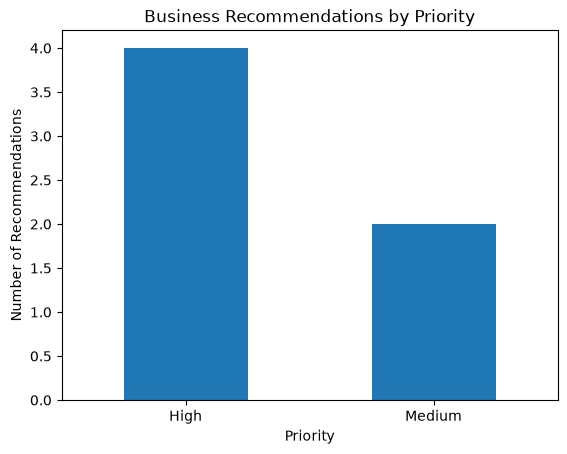

In [252]:
priority_summary.plot(
    kind='bar',
    title='Business Recommendations by Priority',
    xlabel='Priority',
    ylabel='Number of Recommendations',
    rot=0
)

plt.show()

In [253]:
priority_percentage = (
    business_strategy['Priority']
    .value_counts(normalize=True) * 100
)

priority_percentage = priority_percentage.round(2)

display(priority_percentage)

Priority
High      66.67
Medium    33.33
Name: proportion, dtype: float64

In [254]:
business_strategy['Action Timeline'] = [
    'Next 30 Days',
    'Next 30 Days',
    'Next 60 Days',
    'Next 30 Days',
    'Next 60 Days',
    'Next 90 Days'
]

business_action_plan = business_strategy[
    [
        'Business Area',
        'Priority',
        'Recommendation',
        'Action Timeline'
    ]
]

display(business_action_plan)

,Business Area,Priority,Recommendation,Action Timeline
0,Sales Performance,High,Analyze seasonal sales trends and plan promoti...,Next 30 Days
1,Customer Retention,High,Introduce loyalty programs and personalized of...,Next 30 Days
2,Product Performance,Medium,Focus marketing efforts on high-revenue produc...,Next 60 Days
3,Customer Behaviour,High,Use personalized discounts to encourage second...,Next 30 Days
4,Churn Analysis,High,Create targeted retention campaigns for inacti...,Next 60 Days
5,Machine Learning,Medium,Improve model features and handle class imbala...,Next 90 Days


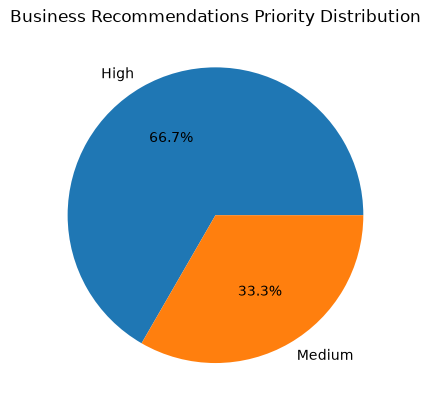

In [255]:
priority_percentage.plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Business Recommendations Priority Distribution',
    ylabel=''
)

plt.show()

In [256]:
final_business_summary = business_strategy[
    [
        'Business Area',
        'Key Finding',
        'Priority',
        'Recommendation',
        'Action Timeline'
    ]
].copy()

display(final_business_summary)

,Business Area,Key Finding,Priority,Recommendation,Action Timeline
0,Sales Performance,November 2017 had the highest monthly revenue,High,Analyze seasonal sales trends and plan promoti...,Next 30 Days
1,Customer Retention,Repeat buyer rate was approximately 3%,High,Introduce loyalty programs and personalized of...,Next 30 Days
2,Product Performance,Health & Beauty was the top revenue category,Medium,Focus marketing efforts on high-revenue produc...,Next 60 Days
3,Customer Behaviour,Approximately 97% of customers purchased only ...,High,Use personalized discounts to encourage second...,Next 30 Days
4,Churn Analysis,99.02% had no observed purchase in the 180-day...,High,Create targeted retention campaigns for inacti...,Next 60 Days
5,Machine Learning,Logistic Regression had the highest balanced a...,Medium,Improve model features and handle class imbala...,Next 90 Days


In [257]:
from pathlib import Path

project_path = Path.cwd()

print("Current Location:", project_path)

print("\nProject Files and Folders:")

for item in sorted(project_path.iterdir()):
    print(item.name)

Current Location: d:\VS CODE\Data_Science_Projects\Project_1_Ecommerce\notebooks

Project Files and Folders:
01_dataset_exploration.ipynb


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

final_model_comparison = pd.DataFrame({
    'Model': [
        'Dummy Baseline',
        'Logistic Regression',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_dummy),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, y_pred_dummy),
        balanced_accuracy_score(y_test, y_pred_lr),
        balanced_accuracy_score(y_test, y_pred_rf)
    ],
    'Macro F1': [
        f1_score(y_test, y_pred_dummy, average='macro'),
        f1_score(y_test, y_pred_lr, average='macro'),
        f1_score(y_test, y_pred_rf, average='macro')
    ]
})

display(final_model_comparison)

,Model,Accuracy,Balanced Accuracy,Macro F1
0,Dummy Baseline,0.996493,0.500000,0.499122
1,Logistic Regression,0.571956,0.531734,0.367543
2,Random Forest,0.994278,0.498889,0.498565


In [258]:
from pathlib import Path

project_path = Path.cwd().parent

print("Project Root:", project_path)

print("\nProject Structure:")

for item in sorted(project_path.iterdir()):
    if item.is_dir():
        print(f"📁 {item.name}/")
    else:
        print(f"📄 {item.name}")

Project Root: d:\VS CODE\Data_Science_Projects\Project_1_Ecommerce

Project Structure:
📁 dashboards/
📁 data/
📁 notebooks/
📄 README.md
📁 sql/
📁 src/


In [259]:
data_path = project_path / "data"

print("DATA DIRECTORY STRUCTURE\n")

for item in sorted(data_path.rglob("*")):
    if item.is_dir():
        print(f"📁 {item.relative_to(project_path)}/")
    else:
        print(f"📄 {item.relative_to(project_path)}")

DATA DIRECTORY STRUCTURE

📄 data\cleaned_delivered_sales.csv
📁 data\raw/
📄 data\raw\olist_customers_dataset.csv
📄 data\raw\olist_geolocation_dataset.csv
📄 data\raw\olist_order_items_dataset.csv
📄 data\raw\olist_order_payments_dataset.csv
📄 data\raw\olist_order_reviews_dataset.csv
📄 data\raw\olist_orders_dataset.csv
📄 data\raw\olist_products_dataset.csv
📄 data\raw\olist_sellers_dataset.csv
📄 data\raw\product_category_name_translation.csv


In [260]:
notebook_path = project_path / "notebooks"

print("NOTEBOOK FILES\n")

for item in sorted(notebook_path.iterdir()):
    print(item.name)

NOTEBOOK FILES

01_dataset_exploration.ipynb


In [261]:
import nbformat

notebook_file = notebook_path / "01_dataset_exploration.ipynb"

nb = nbformat.read(notebook_file, as_version=4)

code_cells = [
    cell for cell in nb.cells
    if cell.cell_type == 'code'
]

markdown_cells = [
    cell for cell in nb.cells
    if cell.cell_type == 'markdown'
]

output_cells = [
    cell for cell in code_cells
    if cell.outputs
]

print("NOTEBOOK QUALITY CHECK")
print("----------------------")
print("Total cells:", len(nb.cells))
print("Code cells:", len(code_cells))
print("Markdown cells:", len(markdown_cells))
print("Cells with saved outputs:", len(output_cells))

print("\nMARKDOWN HEADINGS:")

for cell in markdown_cells:
    for line in cell.source.splitlines():
        if line.startswith("#"):
            print(line)

NOTEBOOK QUALITY CHECK
----------------------
Total cells: 182
Code cells: 181
Markdown cells: 1
Cells with saved outputs: 172

MARKDOWN HEADINGS:


In [265]:
nb = nbformat.read(notebook_file, as_version=4)

code_cells = [
    c for c in nb.cells
    if c.cell_type == 'code'
]

markdown_cells = [
    c for c in nb.cells
    if c.cell_type == 'markdown'
]

print("NOTEBOOK QUALITY CHECK")
print("----------------------")
print("Total cells:", len(nb.cells))
print("Code cells:", len(code_cells))
print("Markdown cells:", len(markdown_cells))

print("\nMARKDOWN SECTIONS:")

for i, cell in enumerate(markdown_cells, start=1):
    heading = cell.source.strip().splitlines()

    if heading:
        print(f"{i}. {heading[0]}")
    else:
        print(f"{i}. Empty Markdown cell")

NOTEBOOK QUALITY CHECK
----------------------
Total cells: 195
Code cells: 179
Markdown cells: 16

MARKDOWN SECTIONS:
1. # E-commerce Sales Forecasting and Customer Churn Prediction
2. ## 2. Business Problem
3. ## 3. Dataset Description
4. ## 4. Importing Libraries
5. ## 5. Data Loading and Initial Exploration
6. ## 6. Data Cleaning and Preparation
7. ## 7. Exploratory Data Analysis (EDA)
8. ## 8. Product and Category Performance
9. ## 9. Customer Behaviour and Retention Analysis
10. ## 10. Sales Forecasting
11. ## 11. Customer Churn Analysis
12. ## 12. Feature Engineering and Dataset Preparation
13. ## 13. Machine Learning Model Development
14. ## 14. Model Evaluation and Comparison
15. ## 15. Business Insights and Recommendations
16. ## 16. Final Conclusion


In [266]:
output_cells = [
    cell for cell in code_cells
    if cell.outputs
]

error_cells = [
    cell for cell in code_cells
    if any(
        output.output_type == 'error'
        for output in cell.outputs
    )
]

print("Code cells:", len(code_cells))
print("Cells with saved outputs:", len(output_cells))
print("Cells with saved errors:", len(error_cells))

Code cells: 179
Cells with saved outputs: 171
Cells with saved errors: 0


In [267]:
import importlib.metadata as metadata

packages = [
    'pandas',
    'numpy',
    'matplotlib',
    'seaborn',
    'scikit-learn',
    'jupyter',
    'openpyxl'
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}=={version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas==3.1.0
numpy==2.5.4
matplotlib==3.11.2
seaborn==0.13.2
scikit-learn==1.9.1
jupyter==1.1.1
openpyxl==3.1.5


In [268]:
from pathlib import Path

project_path = Path.cwd().parent

print("FINAL PROJECT STRUCTURE\n")

for item in sorted(project_path.rglob("*")):
    if item.is_dir():
        print(f"📁 {item.relative_to(project_path)}/")
    else:
        print(f"📄 {item.relative_to(project_path)}")

FINAL PROJECT STRUCTURE

📁 dashboards/
📁 data/
📄 data\cleaned_delivered_sales.csv
📁 data\raw/
📄 data\raw\olist_customers_dataset.csv
📄 data\raw\olist_geolocation_dataset.csv
📄 data\raw\olist_order_items_dataset.csv
📄 data\raw\olist_order_payments_dataset.csv
📄 data\raw\olist_order_reviews_dataset.csv
📄 data\raw\olist_orders_dataset.csv
📄 data\raw\olist_products_dataset.csv
📄 data\raw\olist_sellers_dataset.csv
📄 data\raw\product_category_name_translation.csv
📁 notebooks/
📄 notebooks\01_dataset_exploration.ipynb
📄 README.md
📄 requirements.txt
📁 sql/
📁 src/
